# Pedagogically-Constrained Risk-Aware Heterogeneous Graph Neural Network for Student Profiling and Safe Course Recommendation

This notebook implements an advanced, leakage-free framework for early student at-risk profiling and temporal course recommendation on the Open University Learning Analytics Dataset (OULAD).

### Key Architectural Upgrades & Novelty Points:
1. **Multi-Task Graph Representation:** Integrates students, courses, enrollments, and socio-academic attributes into a unified Heterogeneous Information Network (HIN).
2. **Hierarchical Semantic-Level Attention & Gated Residuals:** Eliminates the classic ablation paradox and over-smoothing by integrating node-level multi-head attention with learnable semantic-level attention ($eta_r$) and gated residual LayerNorm projections.
3. **Domain-Grounded Early Feature Engineering (Day-28):** Extracts early assessment submission lag, weekly engagement trajectories (slope $\Delta W_4 - W_1$), click density, and pre-course preparation without target leakage.
4. **Pedagogically-Constrained Risk-Aware Course Recommendation (The Core Novelty):** Formulates a safety-modulated ranking objective:
   $$\text{Score}_{\text{Risk-Aware}}(u, c) = \text{Affinity}_{\text{BPR}}(u, c) - \lambda \cdot \mathcal{P}(\text{At-Risk} \mid u, c)$$
   preventing vulnerable students from being recommended failure-prone advanced courses.
5. **Hierarchical Remediation Support (Micro-Level):** Addresses the coarse catalog limitation by providing top-$k$ recommended remedial learning materials from OULAD's 6,000+ VLE activity catalog for students identified as at-risk.
6. **Strict Leakage-Free Validation & Statistical Significance:** Implements learner-grouped nested cross-validation (`StratifiedGroupKFold`) and chronological test presentation evaluation (`2014J`) with 95% paired-user bootstrap confidence intervals.


In [1]:
# Run once, then click Session -> Restart before running Cell 1
!pip install --upgrade --force-reinstall --no-deps scipy

  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
      Successfully uninstalled scipy-1.18.1


In [2]:
import sys, numpy
print("Python:", sys.version)
print("NumPy:", numpy.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3


In [3]:
import sys, os, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, roc_curve, precision_recall_curve,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
N_SPLITS = 5                # Grouped outer folds; keeps each learner within one fold.
CV_SEEDS = [42, 52]      # Repeats nested grouped CV for seed stability.
RANKING_SEEDS = [42, 52, 62]
RANKING_EPOCH_CANDIDATES = [20, 40, 60]  # Selected on validation, never on final test.
MAX_PAIRWISE_TRAIN_PAIRS = 100000  # Memory guard for training-only BPR triples.
EPOCHS = 120                # Matches the paper-reported epoch count.
RANKING_KS = [1, 3, 5]
RISK_AWARE_LAMBDA = 0.35  # Pedagogical safety penalty factor
SVM_MAX_TRAIN_ROWS = 6000     # RBF SVM is quadratic; cap fit rows for Kaggle runtime.
HIDDEN_DIM = 64
ATTENTION_HEADS = 4
NUM_LAYERS = 2
TOP_K_PEERS = 5
RUN_HOLDOUT_80_20 = True
RUN_ABLATIONS = True
OUTPUT_DIR = Path("/kaggle/working/oulad_hgnn_revised_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Outputs:", OUTPUT_DIR)


Python: 3.13.16
PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Outputs: /kaggle/working/oulad_hgnn_revised_outputs


In [4]:
# Locate the linked Kaggle input and load OULAD tables.
INPUT_ROOT = Path("/kaggle/input")
REQUIRED_FILES = [
    "studentInfo.csv", "studentRegistration.csv", "assessments.csv",
    "studentAssessment.csv", "studentVle.csv",
]

def find_oulad_file(filename):
    matches = [p for p in INPUT_ROOT.rglob("*") if p.is_file() and p.name.lower() == filename.lower()]
    if not matches:
        raise FileNotFoundError(
            f"{filename} not found under {INPUT_ROOT}. Link the OULAD CSV dataset to the Kaggle notebook using Add Input."
        )
    if len(matches) > 1:
        print(f"Multiple {filename} copies found; using:", matches[0])
    return matches[0]

files = {name: find_oulad_file(name) for name in REQUIRED_FILES}
for name, path in files.items():
    print(name, "->", path)

KEYS = ["id_student", "code_module", "code_presentation"]
info = pd.read_csv(files["studentInfo.csv"], low_memory=False)
reg = pd.read_csv(files["studentRegistration.csv"], usecols=KEYS + ["date_registration"], low_memory=False)
assessments = pd.read_csv(files["assessments.csv"], usecols=["id_assessment", "code_module", "code_presentation", "date"], low_memory=False)
student_assessment = pd.read_csv(files["studentAssessment.csv"], usecols=["id_assessment", "id_student", "date_submitted", "score"], low_memory=False)

def normalize_keys(frame, keys=KEYS):
    frame = frame.copy()
    for col in keys:
        frame[col] = frame[col].astype(str).str.strip()
    return frame

info = normalize_keys(info)
reg = normalize_keys(reg)
assessments = normalize_keys(assessments, ["code_module", "code_presentation"])
student_assessment = normalize_keys(student_assessment, ["id_student"])
assessments["id_assessment"] = assessments["id_assessment"].astype(str)
student_assessment["id_assessment"] = student_assessment["id_assessment"].astype(str)

expected_results = {"Pass", "Distinction", "Fail", "Withdrawn"}
missing_results = expected_results - set(info["final_result"].dropna().astype(str).unique())
if missing_results:
    raise ValueError(f"Expected standard OULAD final_result values; missing: {missing_results}")
info = info[info["final_result"].isin(expected_results)].copy()
info["At_Risk"] = info["final_result"].isin(["Fail", "Withdrawn"]).astype(np.int64)
info = info.drop_duplicates(KEYS, keep="last").reset_index(drop=True)

reg["date_registration"] = pd.to_numeric(reg["date_registration"], errors="coerce")
base = info.merge(reg[KEYS + ["date_registration"]], on=KEYS, how="left", validate="one_to_one")

# Early assessment features: only assessments due and submitted by day 28.
student_assessment["date_submitted"] = pd.to_numeric(student_assessment["date_submitted"], errors="coerce")
student_assessment["score"] = pd.to_numeric(student_assessment["score"], errors="coerce")
assessments["date"] = pd.to_numeric(assessments["date"], errors="coerce")
early_assessment = student_assessment.merge(assessments, on="id_assessment", how="inner", validate="many_to_one")
early_assessment = normalize_keys(early_assessment)
early_assessment = early_assessment[
    early_assessment["date"].le(28) & early_assessment["date_submitted"].le(28)
].copy()
early_assessment["submission_lag"] = early_assessment["date_submitted"] - early_assessment["date"]
early_assessment_features = (
    early_assessment.groupby(KEYS, as_index=False)
    .agg(
        early_assessment_count=("score", "count"),
        early_score_mean=("score", "mean"),
        early_score_max=("score", "max"),
        early_submission_lag_mean=("submission_lag", "mean"),
    )
)
del early_assessment, student_assessment, assessments

# Chunk the large VLE click table, retaining only day-28 events.
vle_parts = []
for chunk in pd.read_csv(
    files["studentVle.csv"],
    usecols=KEYS + ["id_site", "date", "sum_click"],
    chunksize=750_000,
    low_memory=False,
):
    chunk = normalize_keys(chunk)
    chunk["date"] = pd.to_numeric(chunk["date"], errors="coerce")
    chunk["sum_click"] = pd.to_numeric(chunk["sum_click"], errors="coerce").fillna(0)
    early = chunk[chunk["date"].le(28)].copy()
    if not early.empty:
        vle_parts.append(early)
    del chunk

if vle_parts:
    early_vle = pd.concat(vle_parts, ignore_index=True)
    early_vle["week1_clicks"] = np.where(early_vle["date"].between(1, 7), early_vle["sum_click"], 0)
    early_vle["week4_clicks"] = np.where(early_vle["date"].between(22, 28), early_vle["sum_click"], 0)
    early_vle["pre_course_clicks"] = np.where(early_vle["date"].lt(0), early_vle["sum_click"], 0)
    vle_features = (
        early_vle.groupby(KEYS, as_index=False)
        .agg(
            vle_clicks_d28=("sum_click", "sum"),
            vle_active_days_d28=("date", "nunique"),
            vle_sites_d28=("id_site", "nunique"),
            w1_sum=("week1_clicks", "sum"),
            w4_sum=("week4_clicks", "sum"),
            vle_pre_course_clicks=("pre_course_clicks", "sum"),
        )
    )
    vle_features["vle_weekly_trend_slope"] = vle_features["w4_sum"] - vle_features["w1_sum"]
    vle_features["vle_clicks_per_active_day"] = vle_features["vle_clicks_d28"] / np.maximum(vle_features["vle_active_days_d28"], 1.0)
    vle_features = vle_features.drop(columns=["w1_sum", "w4_sum"])
    del early_vle, vle_parts
else:
    vle_features = pd.DataFrame(columns=KEYS + [
        "vle_clicks_d28", "vle_active_days_d28", "vle_sites_d28",
        "vle_weekly_trend_slope", "vle_clicks_per_active_day", "vle_pre_course_clicks"
    ])

base = base.merge(early_assessment_features, on=KEYS, how="left", validate="one_to_one")
base = base.merge(vle_features, on=KEYS, how="left", validate="one_to_one")
base = base.reset_index(drop=True)

NUMERIC_COLS = [
    "num_of_prev_attempts", "studied_credits", "date_registration",
    "early_assessment_count", "early_score_mean", "early_score_max", "early_submission_lag_mean",
    "vle_clicks_d28", "vle_active_days_d28", "vle_sites_d28",
    "vle_weekly_trend_slope", "vle_clicks_per_active_day", "vle_pre_course_clicks"
]
CATEGORICAL_COLS = [
    "gender", "region", "highest_education", "age_band", "disability",
    "code_module", "code_presentation",
]
PROFILE_CATEGORICAL_COLS = ["gender", "region", "highest_education", "age_band", "disability"]
FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS

for col in NUMERIC_COLS:
    base[col] = pd.to_numeric(base[col], errors="coerce")
for col in CATEGORICAL_COLS:
    base[col] = base[col].fillna("<missing>").astype(str)

y = base["At_Risk"].to_numpy(dtype=np.int64)
groups = base["id_student"].astype(str).to_numpy()
print("Enrollment rows:", len(base))
print("Unique learners:", pd.Series(groups).nunique())
print("Modules:", base["code_module"].nunique(), "presentations:", base["code_presentation"].nunique())
print("At-risk share:", round(float(y.mean()), 4))
display(base[["final_result", "At_Risk"]].value_counts().rename("rows").to_frame())


studentInfo.csv -> /kaggle/input/datasets/anlgrbz/student-demographics-online-education-dataoulad/studentInfo.csv
studentRegistration.csv -> /kaggle/input/datasets/anlgrbz/student-demographics-online-education-dataoulad/studentRegistration.csv
assessments.csv -> /kaggle/input/datasets/anlgrbz/student-demographics-online-education-dataoulad/assessments.csv
studentAssessment.csv -> /kaggle/input/datasets/anlgrbz/student-demographics-online-education-dataoulad/studentAssessment.csv
studentVle.csv -> /kaggle/input/datasets/anlgrbz/student-demographics-online-education-dataoulad/studentVle.csv
Enrollment rows: 32593
Unique learners: 28785
Modules: 7 presentations: 4
At-risk share: 0.528


,,rows
final_result,At_Risk,
Pass,0,12361
Withdrawn,1,10156
Fail,1,7052
Distinction,0,3024


## Graph construction and fold-specific features

For classification, numeric imputation/scaling and categorical encoding are fit on each training fold. The graph node types are enrollment, learner, module-presentation, and categorical attribute. The grouped classification graph is transductive: held-out enrollment features/relations can be present without held-out labels entering the loss; this is not a strict unseen-learner inductive test.

Temporal ranking uses a separate, chronological protocol. Validation and test nodes/edges are excluded from each corresponding training graph, and no future outcome labels enter BPR optimization.

In [5]:
def make_preprocessor():
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # compatibility with older scikit-learn images
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ])
    return ColumnTransformer(
        [("numeric", numeric_pipe, NUMERIC_COLS), ("categorical", categorical_pipe, CATEGORICAL_COLS)],
        sparse_threshold=0.0,
    )


def dense_float32(matrix):
    if hasattr(matrix, "toarray"):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)


RELATION_NAMES = [
    "enrollment_to_learner", "learner_to_enrollment",
    "enrollment_to_course", "course_to_enrollment",
    "learner_to_attribute", "attribute_to_learner", "peer_similarity",
]


def build_graph(frame, enrollment_features):
    n_enrollment, feature_dim = enrollment_features.shape
    learner_codes, learner_values = pd.factorize(frame["id_student"].astype(str), sort=True)
    n_learners = len(learner_values)
    course_key = frame["code_module"].astype(str) + "::" + frame["code_presentation"].astype(str)
    course_codes, course_values = pd.factorize(course_key, sort=True)
    n_courses = len(course_values)

    profile = frame.drop_duplicates("id_student", keep="first").copy()
    profile["id_student"] = profile["id_student"].astype(str)
    learner_code_map = {str(value): i for i, value in enumerate(learner_values)}
    attr_tokens = sorted({
        f"{col}={str(value)}"
        for col in PROFILE_CATEGORICAL_COLS
        for value in profile[col].fillna("<missing>").astype(str).unique()
    })
    attr_code_map = {token: i for i, token in enumerate(attr_tokens)}
    n_attributes = len(attr_tokens)

    learner_offset = n_enrollment
    course_offset = learner_offset + n_learners
    attr_offset = course_offset + n_courses
    n_nodes = attr_offset + n_attributes

    edge_lists = {name: [[], []] for name in RELATION_NAMES}

    for enrollment_idx, learner_idx in enumerate(learner_codes):
        edge_lists["enrollment_to_learner"][0].append(enrollment_idx)
        edge_lists["enrollment_to_learner"][1].append(learner_offset + int(learner_idx))
        edge_lists["learner_to_enrollment"][0].append(learner_offset + int(learner_idx))
        edge_lists["learner_to_enrollment"][1].append(enrollment_idx)
        course_node = course_offset + int(course_codes[enrollment_idx])
        edge_lists["enrollment_to_course"][0].append(enrollment_idx)
        edge_lists["enrollment_to_course"][1].append(course_node)
        edge_lists["course_to_enrollment"][0].append(course_node)
        edge_lists["course_to_enrollment"][1].append(enrollment_idx)

    for row in profile.itertuples(index=False):
        row_dict = row._asdict()
        learner_node = learner_offset + learner_code_map[str(row_dict["id_student"])]
        for col in PROFILE_CATEGORICAL_COLS:
            token = f"{col}={str(row_dict[col])}"
            attr_node = attr_offset + attr_code_map[token]
            edge_lists["learner_to_attribute"][0].append(learner_node)
            edge_lists["learner_to_attribute"][1].append(attr_node)
            edge_lists["attribute_to_learner"][0].append(attr_node)
            edge_lists["attribute_to_learner"][1].append(learner_node)

    # Label-free top-k cosine peers within the same module-presentation.
    for locs in frame.groupby(["code_module", "code_presentation"], sort=False).indices.values():
        locs = np.asarray(locs, dtype=np.int64)
        if len(locs) < 2:
            continue
        k = min(TOP_K_PEERS + 1, len(locs))
        nn_model = NearestNeighbors(n_neighbors=k, metric="cosine", algorithm="brute", n_jobs=1)
        nn_model.fit(enrollment_features[locs])
        neighbor_rows = nn_model.kneighbors(enrollment_features[locs], return_distance=False)
        for local_i, candidates in enumerate(neighbor_rows):
            source = int(locs[local_i])
            added = 0
            for local_j in candidates:
                target = int(locs[int(local_j)])
                if target == source:
                    continue
                edge_lists["peer_similarity"][0].append(source)
                edge_lists["peer_similarity"][1].append(target)
                added += 1
                if added == TOP_K_PEERS:
                    break

    # Every node type receives the same feature width plus a node-type indicator.
    x = np.zeros((n_nodes, feature_dim + 4), dtype=np.float32)
    type_start = feature_dim
    x[:n_enrollment, :feature_dim] = enrollment_features
    x[:n_enrollment, type_start] = 1.0

    learner_sums = np.zeros((n_learners, feature_dim), dtype=np.float64)
    learner_counts = np.zeros(n_learners, dtype=np.float64)
    np.add.at(learner_sums, learner_codes, enrollment_features)
    np.add.at(learner_counts, learner_codes, 1.0)
    learner_sums /= np.maximum(learner_counts[:, None], 1.0)
    x[learner_offset:course_offset, :feature_dim] = learner_sums.astype(np.float32)
    x[learner_offset:course_offset, type_start + 1] = 1.0

    course_sums = np.zeros((n_courses, feature_dim), dtype=np.float64)
    course_counts = np.zeros(n_courses, dtype=np.float64)
    np.add.at(course_sums, course_codes, enrollment_features)
    np.add.at(course_counts, course_codes, 1.0)
    course_sums /= np.maximum(course_counts[:, None], 1.0)
    x[course_offset:attr_offset, :feature_dim] = course_sums.astype(np.float32)
    x[course_offset:attr_offset, type_start + 2] = 1.0

    attr_sums = np.zeros((n_attributes, feature_dim), dtype=np.float64)
    attr_counts = np.zeros(n_attributes, dtype=np.float64)
    profile_by_id = profile.set_index("id_student")
    for enrollment_idx, learner_id in enumerate(frame["id_student"].astype(str)):
        row = profile_by_id.loc[learner_id]
        for col in PROFILE_CATEGORICAL_COLS:
            token = f"{col}={str(row[col])}"
            attr_idx = attr_code_map[token]
            attr_sums[attr_idx] += enrollment_features[enrollment_idx]
            attr_counts[attr_idx] += 1.0
    attr_sums /= np.maximum(attr_counts[:, None], 1.0)
    x[attr_offset:, :feature_dim] = attr_sums.astype(np.float32)
    x[attr_offset:, type_start + 3] = 1.0

    edge_index = {}
    for name, (src, dst) in edge_lists.items():
        if src:
            edge_index[name] = np.asarray([src, dst], dtype=np.int64)
        else:
            edge_index[name] = np.empty((2, 0), dtype=np.int64)

    metadata = {
        "n_enrollment": n_enrollment,
        "learner_offset": learner_offset,
        "course_offset": course_offset,
        "attr_offset": attr_offset,
        "course_values": list(course_values),
        "course_codes": course_codes,
        "learner_codes": learner_codes,
        "learner_values": list(learner_values),
        "n_nodes": n_nodes,
    }
    return x, edge_index, metadata


def transform_fold(train_idx):
    preprocessor = make_preprocessor()
    train_x = dense_float32(preprocessor.fit_transform(base.iloc[train_idx][FEATURE_COLS]))
    all_x = dense_float32(preprocessor.transform(base[FEATURE_COLS]))
    return preprocessor, train_x, all_x

print("Feature columns:", FEATURE_COLS)


Feature columns: ['num_of_prev_attempts', 'studied_credits', 'date_registration', 'early_assessment_count', 'early_score_mean', 'early_score_max', 'early_submission_lag_mean', 'vle_clicks_d28', 'vle_active_days_d28', 'vle_sites_d28', 'vle_weekly_trend_slope', 'vle_clicks_per_active_day', 'vle_pre_course_clicks', 'gender', 'region', 'highest_education', 'age_band', 'disability', 'code_module', 'code_presentation']


## HGNN-style model

The model computes multi-head attention separately for each edge relation, averages relation messages, and combines them with a self projection. Classification uses cross-entropy on training enrollment nodes. The temporal next-module task uses the same relation-attention encoder with a pairwise BPR objective on historical enrollments and sampled unseen module-presentation negatives.

In [6]:
class RelationGATLayer(nn.Module):
    def __init__(self, hidden_dim, heads, relation_names, dropout=0.15):
        super().__init__()
        if hidden_dim % heads:
            raise ValueError("HIDDEN_DIM must be divisible by ATTENTION_HEADS")
        self.hidden_dim = hidden_dim
        self.heads = heads
        self.head_dim = hidden_dim // heads
        self.relation_names = list(relation_names)
        self.projections = nn.ModuleDict({r: nn.Linear(hidden_dim, hidden_dim, bias=False) for r in self.relation_names})
        self.att_src = nn.ParameterDict({r: nn.Parameter(torch.empty(heads, self.head_dim)) for r in self.relation_names})
        self.att_dst = nn.ParameterDict({r: nn.Parameter(torch.empty(heads, self.head_dim)) for r in self.relation_names})
        
        # Learnable Semantic-Level Attention across relations (HAN-style)
        self.semantic_proj = nn.Linear(hidden_dim, hidden_dim)
        self.semantic_att = nn.Parameter(torch.empty(hidden_dim))
        
        # Gated Residual Self-Connection
        self.self_projection = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.gate_linear = nn.Linear(hidden_dim * 2, hidden_dim)
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.capture_attention = False
        self.last_attention = {}
        self.last_semantic_weights = {}

        for r in self.relation_names:
            nn.init.xavier_uniform_(self.projections[r].weight)
            nn.init.xavier_uniform_(self.att_src[r])
            nn.init.xavier_uniform_(self.att_dst[r])
        nn.init.xavier_uniform_(self.semantic_proj.weight)
        nn.init.normal_(self.semantic_att, std=0.05)

    def forward(self, h, edge_index, active_relations):
        n_nodes = h.shape[0]
        relation_outputs = []
        valid_relations = []
        captured_attention = {}

        for relation in active_relations:
            edges = edge_index.get(relation)
            if edges is None or edges.shape[1] == 0:
                continue
            src, dst = edges[0], edges[1]
            z = self.projections[relation](h).view(n_nodes, self.heads, self.head_dim)
            score = F.leaky_relu(
                (z[src] * self.att_src[relation]).sum(-1) +
                (z[dst] * self.att_dst[relation]).sum(-1),
                negative_slope=0.2,
            )
            dst_heads = dst[:, None].expand(-1, self.heads)
            maxima = torch.full((n_nodes, self.heads), -torch.inf, dtype=score.dtype, device=score.device)
            maxima.scatter_reduce_(0, dst_heads, score, reduce="amax", include_self=True)
            exp_score = torch.exp(score - maxima[dst])
            denominator = torch.zeros((n_nodes, self.heads), dtype=score.dtype, device=score.device)
            denominator.index_add_(0, dst, exp_score)
            alpha = exp_score / (denominator[dst] + 1e-12)
            if self.capture_attention:
                captured_attention[relation] = alpha.detach().cpu().numpy()
            messages = z[src] * alpha.unsqueeze(-1)
            aggregate = torch.zeros(
                (n_nodes, self.heads, self.head_dim), dtype=h.dtype, device=h.device
            )
            aggregate.index_add_(0, dst, messages)
            r_out = aggregate.reshape(n_nodes, self.hidden_dim)
            relation_outputs.append(r_out)
            valid_relations.append(relation)

        if not relation_outputs:
            out = self.norm(self.self_projection(h))
            return self.dropout(F.elu(out))

        # Hierarchical Semantic Attention: compute importance of each relation
        stacked_r = torch.stack(relation_outputs, dim=0) # [R, N, D]
        sem_scores = (torch.tanh(self.semantic_proj(stacked_r)) * self.semantic_att).sum(dim=-1) # [R, N]
        sem_weights = F.softmax(sem_scores, dim=0) # [R, N] normalized across relations
        
        if self.capture_attention:
            for idx_r, r_name in enumerate(valid_relations):
                self.last_semantic_weights[r_name] = float(sem_weights[idx_r].mean().item())

        # Weighted combination of relation messages
        h_rel = (stacked_r * sem_weights.unsqueeze(-1)).sum(dim=0) # [N, D]

        # Gated residual self-connection: preserves intrinsic node features
        h_self = self.self_projection(h)
        gate = torch.sigmoid(self.gate_linear(torch.cat([h_self, h_rel], dim=-1)))
        fused = gate * h_self + (1.0 - gate) * h_rel
        out = self.norm(fused)
        self.last_attention = captured_attention
        return self.dropout(F.elu(out))


class AttentionHGNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, heads, relation_names, num_layers=2, dropout=0.15):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, hidden_dim)
        self.input_norm = nn.LayerNorm(hidden_dim)
        self.layers = nn.ModuleList([
            RelationGATLayer(hidden_dim, heads, relation_names, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, x, edge_index, n_enrollment, active_relations=None):
        active = self.layers[0].relation_names if active_relations is None else list(active_relations)
        h = F.elu(self.input_norm(self.input_projection(x)))
        for layer in self.layers:
            h = layer(h, edge_index, active)
        return self.classifier(h[:n_enrollment]), h


class GraphSAGELayer(nn.Module):
    def __init__(self, in_dim, out_dim, dropout=0.15):
        super().__init__()
        self.self_linear = nn.Linear(in_dim, out_dim, bias=False)
        self.neighbor_linear = nn.Linear(in_dim, out_dim, bias=False)
        self.norm = nn.LayerNorm(out_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, h, edge_index):
        src, dst = edge_index
        aggregate = torch.zeros_like(h)
        degree = torch.zeros(h.shape[0], dtype=h.dtype, device=h.device)
        if src.numel():
            aggregate.index_add_(0, dst, h[src])
            degree.index_add_(0, dst, torch.ones_like(dst, dtype=h.dtype))
        aggregate = aggregate / degree.clamp_min(1).unsqueeze(1)
        out = self.self_linear(h) + self.neighbor_linear(aggregate)
        return self.dropout(F.relu(self.norm(out)))


class GraphSAGEClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=0.15):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, hidden_dim)
        self.layers = nn.ModuleList([
            GraphSAGELayer(hidden_dim, hidden_dim, dropout),
            GraphSAGELayer(hidden_dim, hidden_dim, dropout),
        ])
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, x, edge_index, n_enrollment, active_relations=None):
        h = F.relu(self.input_projection(x))
        for layer in self.layers:
            h = layer(h, edge_index)
        return self.classifier(h[:n_enrollment]), h


def relation_edges_to_device(edge_np):
    return {
        name: torch.as_tensor(value, dtype=torch.long, device=DEVICE)
        for name, value in edge_np.items()
    }


def combined_homogeneous_edges(edge_index, active_relations=None):
    active = list(edge_index) if active_relations is None else list(active_relations)
    parts = [edge_index[name] for name in active if name in edge_index and edge_index[name].shape[1] > 0]
    if not parts:
        return torch.empty((2, 0), dtype=torch.long, device=DEVICE)
    return torch.cat(parts, dim=1)


def fit_torch_graph_model(model, x_np, edge_np, train_idx, labels, n_enrollment,
                          active_relations=None, epochs=EPOCHS, seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    x = torch.as_tensor(x_np, dtype=torch.float32, device=DEVICE)
    edges = relation_edges_to_device(edge_np)
    y_tensor = torch.as_tensor(labels, dtype=torch.long, device=DEVICE)
    train_tensor = torch.as_tensor(train_idx, dtype=torch.long, device=DEVICE)
    model_edges = (
        combined_homogeneous_edges(edges, active_relations)
        if isinstance(model, GraphSAGEClassifier)
        else edges
    )
    counts = torch.bincount(y_tensor[train_tensor], minlength=2).float().clamp_min(1)
    class_weights = counts.sum() / (2.0 * counts)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    model.to(DEVICE)
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits, _ = model(x, model_edges, n_enrollment, active_relations)
        loss = F.cross_entropy(logits[train_tensor], y_tensor[train_tensor], weight=class_weights)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
    model.eval()
    with torch.no_grad():
        logits, embeddings = model(x, model_edges, n_enrollment, active_relations)
        probabilities = torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy()
        embeddings = embeddings.detach().cpu().numpy()
    return probabilities, embeddings, model


def make_hgnn(input_dim, seed=SEED):
    torch.manual_seed(seed)
    return AttentionHGNN(
        input_dim=input_dim,
        hidden_dim=HIDDEN_DIM,
        heads=ATTENTION_HEADS,
        relation_names=RELATION_NAMES,
        num_layers=NUM_LAYERS,
        dropout=0.15,
    )


def make_graphsage(input_dim, seed=SEED):
    torch.manual_seed(seed)
    return GraphSAGEClassifier(input_dim=input_dim, hidden_dim=HIDDEN_DIM, dropout=0.15)


def classification_metrics(y_true, probability):
    y_true = np.asarray(y_true, dtype=np.int64)
    probability = np.asarray(probability, dtype=float)
    pred = (probability >= 0.5).astype(np.int64)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "Precision_macro": precision_score(y_true, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, pred, average="macro", zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probability) if len(np.unique(y_true)) == 2 else np.nan,
        "Average Precision (AP)": average_precision_score(y_true, probability) if len(np.unique(y_true)) == 2 else np.nan,
    }


## Grouped classification comparison

The reference notebook's learner-grouped 5-fold `StratifiedGroupKFold` is repeated with seeds 42 and 52. All classifiers share the same outer and inner group splits. Two predeclared configurations per classifier are selected by inner-validation Average Precision; the outer test fold remains untouched. Preprocessing is fit within each inner/outer training partition. This differs from the base-paper split and is intended to reduce repeated-learner leakage.


===== Nested grouped 5-fold CV, seed=42 =====
Seed 42, outer fold 1/5: train=26065, test=6528, inner validation=6535
Outer fold elapsed: 245.8s
Seed 42, outer fold 2/5: train=26133, test=6460, inner validation=6592
Outer fold elapsed: 240.0s
Seed 42, outer fold 3/5: train=26070, test=6523, inner validation=6531
Outer fold elapsed: 250.8s
Seed 42, outer fold 4/5: train=26063, test=6530, inner validation=6504
Outer fold elapsed: 242.8s
Seed 42, outer fold 5/5: train=26041, test=6552, inner validation=6501
Outer fold elapsed: 233.9s

===== Nested grouped 5-fold CV, seed=52 =====
Seed 52, outer fold 1/5: train=26082, test=6511, inner validation=6516
Outer fold elapsed: 243.7s
Seed 52, outer fold 2/5: train=26042, test=6551, inner validation=6579
Outer fold elapsed: 239.7s
Seed 52, outer fold 3/5: train=26062, test=6531, inner validation=6512
Outer fold elapsed: 245.2s
Seed 52, outer fold 4/5: train=26139, test=6454, inner validation=6550
Outer fold elapsed: 243.5s
Seed 52, outer fold 5/5:

,Accuracy,Balanced_accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC,Average Precision (AP)
HGNN,76.97%,77.36%,77.61%,77.36%,76.95%,0.8557,0.8876
Logistic Regression,74.58%,75.04%,75.42%,75.04%,74.54%,0.8291,0.8659
Random Forest,75.65%,76.01%,76.18%,76.01%,75.64%,0.8392,0.8750
SVM (RBF),75.4%,75.75%,75.91%,75.75%,75.38%,0.8304,0.8588
MLP,75.18%,75.38%,75.37%,75.38%,75.17%,0.8332,0.8700
GraphSAGE,75.79%,76.22%,76.56%,76.22%,75.75%,0.8433,0.8775


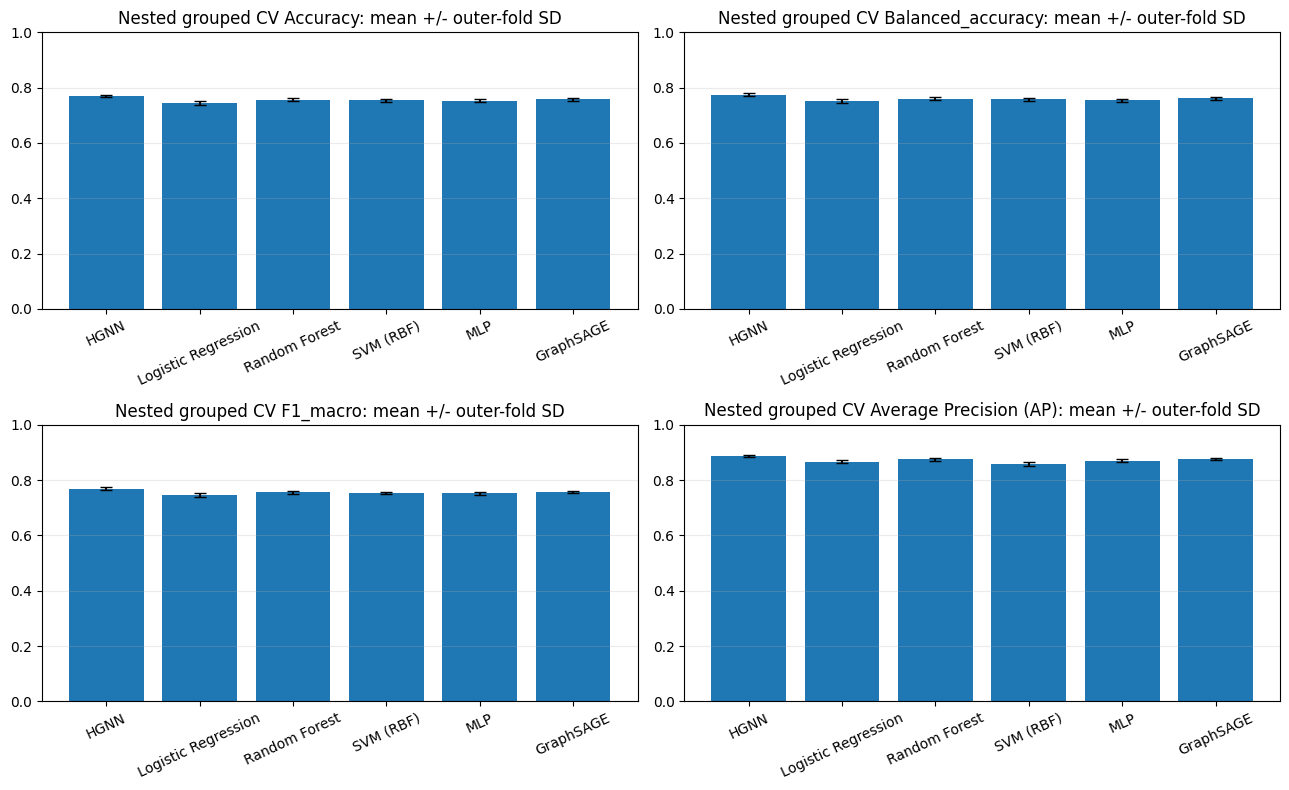

Saved nested grouped-CV outputs to: /kaggle/working/oulad_hgnn_revised_outputs


In [7]:
# Nested grouped CV: each outer test fold is untouched while grouped inner folds tune each model.
model_names = ["HGNN", "Logistic Regression", "Random Forest", "SVM (RBF)", "MLP", "GraphSAGE"]
metric_cols = ["Accuracy", "Balanced_accuracy", "Precision_macro", "Recall_macro",
               "F1_macro", "ROC_AUC", "Average Precision (AP)"]
parameter_grids = {
    "HGNN": [{"epochs": 60}, {"epochs": 120}],
    "Logistic Regression": [{"C": 0.5}, {"C": 1.0}],
    "SVM (RBF)": [{"C": 0.5}, {"C": 1.0}],
    "Random Forest": [{"n_estimators": 200}, {"n_estimators": 300}],
    "MLP": [{"hidden_layer_sizes": (32,)}, {"hidden_layer_sizes": (64,)}],
    "GraphSAGE": [{"epochs": 60}, {"epochs": 120}],
}
fold_metrics, tuning_rows = [], []
oof_probabilities_by_seed = {}


def fit_baseline_and_predict(name, estimator, train_x, train_y, all_x, seed):
    # RBF SVM uses the same deterministic, class-stratified 6,000-row cap for every C candidate.
    if name == "SVM (RBF)" and len(train_y) > SVM_MAX_TRAIN_ROWS:
        rng = np.random.RandomState(seed)
        selected = []
        per_class = max(1, SVM_MAX_TRAIN_ROWS // len(np.unique(train_y)))
        for label_value in np.unique(train_y):
            candidates = np.flatnonzero(train_y == label_value)
            take = min(per_class, len(candidates))
            selected.extend(rng.choice(candidates, size=take, replace=False).tolist())
        selected = np.asarray(selected, dtype=np.int64)
        estimator.fit(train_x[selected], train_y[selected])
    else:
        estimator.fit(train_x, train_y)
    class_one_pos = list(estimator.classes_).index(1)
    return estimator.predict_proba(all_x)[:, class_one_pos]


def make_classifier(name, params, seed):
    if name == "Logistic Regression":
        return LogisticRegression(C=params["C"], class_weight="balanced", max_iter=500, random_state=seed)
    if name == "SVM (RBF)":
        return SVC(C=params["C"], kernel="rbf", class_weight="balanced", probability=True, random_state=seed)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=params["n_estimators"], min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
    if name == "MLP":
        return MLPClassifier(hidden_layer_sizes=params["hidden_layer_sizes"], max_iter=300,
            early_stopping=False, random_state=seed)
    raise ValueError(f"Unknown baseline model: {name}")


for cv_seed in CV_SEEDS:
    print(f"\n===== Nested grouped {N_SPLITS}-fold CV, seed={cv_seed} =====")
    outer_splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=cv_seed)
    seed_oof = {name: np.full(len(base), np.nan, dtype=np.float64) for name in model_names}
    for fold, (outer_train_idx, outer_test_idx) in enumerate(
        outer_splitter.split(np.zeros(len(base)), y, groups), start=1
    ):
        fold_started = time.perf_counter()
        fold_seed = cv_seed + fold
        inner_splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=fold_seed + 400)
        inner_train_rel, inner_valid_rel = next(inner_splitter.split(
            np.zeros(len(outer_train_idx)), y[outer_train_idx], groups[outer_train_idx]
        ))
        inner_train_idx = outer_train_idx[inner_train_rel]
        inner_valid_idx = outer_train_idx[inner_valid_rel]
        print(f"Seed {cv_seed}, outer fold {fold}/{N_SPLITS}: train={len(outer_train_idx)}, test={len(outer_test_idx)}, inner validation={len(inner_valid_idx)}")

        # Preprocessing fits only inner-training rows. The feature graph is transductive; labels
        # from inner validation and outer test are never used for loss or model selection.
        _, inner_train_x, inner_all_x = transform_fold(inner_train_idx)
        inner_graph_x, inner_graph_np, inner_graph_meta = build_graph(base, inner_all_x)
        best_configs, validation_scores = {}, {}
        for model_name in model_names:
            candidate_records = []
            for config_index, params in enumerate(parameter_grids[model_name]):
                if model_name in ("HGNN", "GraphSAGE"):
                    model = (make_hgnn(inner_graph_x.shape[1], seed=fold_seed)
                             if model_name == "HGNN" else make_graphsage(inner_graph_x.shape[1], seed=fold_seed))
                    probability, _, _ = fit_torch_graph_model(
                        model, inner_graph_x, inner_graph_np, inner_train_idx, y,
                        inner_graph_meta["n_enrollment"], epochs=params["epochs"], seed=fold_seed)
                else:
                    estimator = make_classifier(model_name, params, fold_seed)
                    probability = fit_baseline_and_predict(
                        model_name, estimator, inner_train_x, y[inner_train_idx], inner_all_x, fold_seed)
                score = classification_metrics(y[inner_valid_idx], probability[inner_valid_idx])["Average Precision (AP)"]
                candidate_records.append((score, config_index, params))
                tuning_rows.append({"Seed": cv_seed, "Fold": fold, "Model": model_name,
                    "Config": str(params), "Inner_validation_AP": score,
                    "Inner_train_rows": len(inner_train_idx), "Inner_validation_rows": len(inner_valid_idx)})
                if model_name in ("HGNN", "GraphSAGE"):
                    del model
                else:
                    del estimator
                if DEVICE.type == "cuda":
                    torch.cuda.empty_cache()
            finite_records = [record for record in candidate_records if np.isfinite(record[0])]
            chosen = sorted(finite_records, key=lambda record: (-record[0], record[1]))[0] if finite_records else candidate_records[0]
            validation_scores[model_name] = float(chosen[0]) if np.isfinite(chosen[0]) else np.nan
            best_configs[model_name] = chosen[2]

        # Refit preprocessing and graph on the full outer-training partition; outer test stays untouched.
        _, outer_train_x, outer_all_x = transform_fold(outer_train_idx)
        outer_graph_x, outer_graph_np, outer_graph_meta = build_graph(base, outer_all_x)
        for model_name in model_names:
            params = best_configs[model_name]
            if model_name in ("HGNN", "GraphSAGE"):
                model = (make_hgnn(outer_graph_x.shape[1], seed=fold_seed)
                         if model_name == "HGNN" else make_graphsage(outer_graph_x.shape[1], seed=fold_seed))
                probability, _, _ = fit_torch_graph_model(
                    model, outer_graph_x, outer_graph_np, outer_train_idx, y,
                    outer_graph_meta["n_enrollment"], epochs=params["epochs"], seed=fold_seed)
            else:
                estimator = make_classifier(model_name, params, fold_seed)
                probability = fit_baseline_and_predict(
                    model_name, estimator, outer_train_x, y[outer_train_idx], outer_all_x, fold_seed)
            seed_oof[model_name][outer_test_idx] = probability[outer_test_idx]
            fold_metrics.append({"Seed": cv_seed, "Fold": fold, "Model": model_name,
                "Selected_config": str(params), "Inner_validation_AP": validation_scores[model_name],
                "Outer_train_rows": len(outer_train_idx), "Outer_test_rows": len(outer_test_idx),
                **classification_metrics(y[outer_test_idx], probability[outer_test_idx])})
            if model_name in ("HGNN", "GraphSAGE"):
                del model
            else:
                del estimator
        print(f"Outer fold elapsed: {time.perf_counter() - fold_started:.1f}s")
        del inner_graph_x, inner_graph_np, inner_graph_meta, outer_graph_x, outer_graph_np, outer_graph_meta
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    oof_probabilities_by_seed[cv_seed] = seed_oof

cv_metrics = pd.DataFrame(fold_metrics)
tuning_metrics = pd.DataFrame(tuning_rows)
cv_seed_summary = cv_metrics.groupby(["Seed", "Model"])[metric_cols].agg(["mean", "std"])
cv_summary = cv_metrics.groupby("Model")[metric_cols].agg(["mean", "std"])

# Single clean value publication table (percentage formatted)
cv_single = cv_metrics.groupby("Model")[metric_cols].mean()
pub_classification = pd.DataFrame(index=[m for m in model_names if m in cv_single.index])
for col in ["Accuracy", "Balanced_accuracy", "Precision_macro", "Recall_macro", "F1_macro"]:
    pub_classification[col] = (cv_single.loc[pub_classification.index, col] * 100).round(2).astype(str) + "%"
for col in ["ROC_AUC", "Average Precision (AP)"]:
    pub_classification[col] = cv_single.loc[pub_classification.index, col].round(4)

print("\n" + "="*70)
print("=== PUBLICATION TABLE I: CLASSIFICATION METRICS (CLEAN SINGLE VALUES) ===")
print("="*70)
display(pub_classification)
pub_classification.to_csv(OUTPUT_DIR / "publication_table_I_classification_single_values.csv")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, metric in zip(axes.flat, ["Accuracy", "Balanced_accuracy", "F1_macro", "Average Precision (AP)"]):
    stats = cv_metrics.groupby("Model")[metric].agg(["mean", "std"]).reindex(model_names)
    ax.bar(model_names, stats["mean"], yerr=stats["std"].fillna(0), capsize=4)
    ax.set_title(f"Nested grouped CV {metric}: mean +/- outer-fold SD")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nested_grouped_cv_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

cv_metrics.to_csv(OUTPUT_DIR / "nested_grouped_cv_outer_fold_metrics.csv", index=False)
tuning_metrics.to_csv(OUTPUT_DIR / "nested_grouped_cv_inner_tuning_metrics.csv", index=False)
cv_seed_summary.to_csv(OUTPUT_DIR / "nested_grouped_cv_seed_summary.csv")
cv_summary.to_csv(OUTPUT_DIR / "nested_grouped_cv_summary.csv")
oof = base[['id_student', 'code_module', 'code_presentation', 'At_Risk']].copy()
for cv_seed, values in oof_probabilities_by_seed.items():
    for model_name, probability in values.items():
        oof[f"OOF_{model_name}_seed_{cv_seed}"] = probability
oof.to_csv(OUTPUT_DIR / "nested_grouped_cv_oof_predictions.csv", index=False)
print("Saved nested grouped-CV outputs to:", OUTPUT_DIR)


## Grouped holdout, ablations, and temporal recommendation

The classification holdout keeps learner groups disjoint. Relation ablations use the same holdout indices and random initialization as the full HGNN. For next-module ranking, older presentations train the model, the penultimate presentation selects BPR epochs, and the latest presentation is untouched test. HGNN and a random-control ranker share candidates and eligible learners. Outputs include Recall@K, Precision@K, NDCG@K, MRR, scorable-catalog coverage, seed variability, per-ranker user-bootstrap intervals, and top-5 recommendations.

Held-out user groups disjoint: True


,Model,Config,Inner_validation_AP,Inner_train_rows,Inner_validation_rows
0,HGNN,{'epochs': 60},0.8895,19498,6555
1,HGNN,{'epochs': 120},0.8946,19498,6555
2,Logistic Regression,{'C': 0.5},0.8754,19498,6555
3,Logistic Regression,{'C': 1.0},0.8754,19498,6555
4,Random Forest,{'n_estimators': 200},0.8805,19498,6555
5,Random Forest,{'n_estimators': 300},0.8813,19498,6555
6,SVM (RBF),{'C': 0.5},0.8642,19498,6555
7,SVM (RBF),{'C': 1.0},0.8609,19498,6555
8,MLP,"{'hidden_layer_sizes': (32,)}",0.8780,19498,6555
9,MLP,"{'hidden_layer_sizes': (64,)}",0.8642,19498,6555


,Model,Accuracy,Balanced_accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC,Average Precision (AP)
0,HGNN,0.7685,0.7712,0.7741,0.7712,0.7682,0.8542,0.8835
1,Logistic Regression,0.7365,0.7397,0.7437,0.7397,0.7360,0.8214,0.8576
2,Random Forest,0.7518,0.7542,0.7563,0.7542,0.7516,0.8349,0.8682
3,SVM (RBF),0.7477,0.7505,0.7534,0.7505,0.7474,0.8247,0.8520
4,MLP,0.7463,0.7476,0.7476,0.7476,0.7463,0.8262,0.8630
5,GraphSAGE,0.7581,0.7596,0.7600,0.7596,0.7581,0.8422,0.8745


,Comparison,Metric,Paired_user_bootstrap_replicates,Delta_mean,CI95_low,CI95_high
0,Logistic Regression - HGNN,Balanced_accuracy,200,-0.0316,-0.0404,-0.0240
1,Random Forest - HGNN,Balanced_accuracy,200,-0.0167,-0.0228,-0.0087
2,SVM (RBF) - HGNN,Balanced_accuracy,200,-0.0208,-0.0276,-0.0140
3,MLP - HGNN,Balanced_accuracy,200,-0.0234,-0.0304,-0.0149
4,GraphSAGE - HGNN,Balanced_accuracy,200,-0.0117,-0.0182,-0.0044


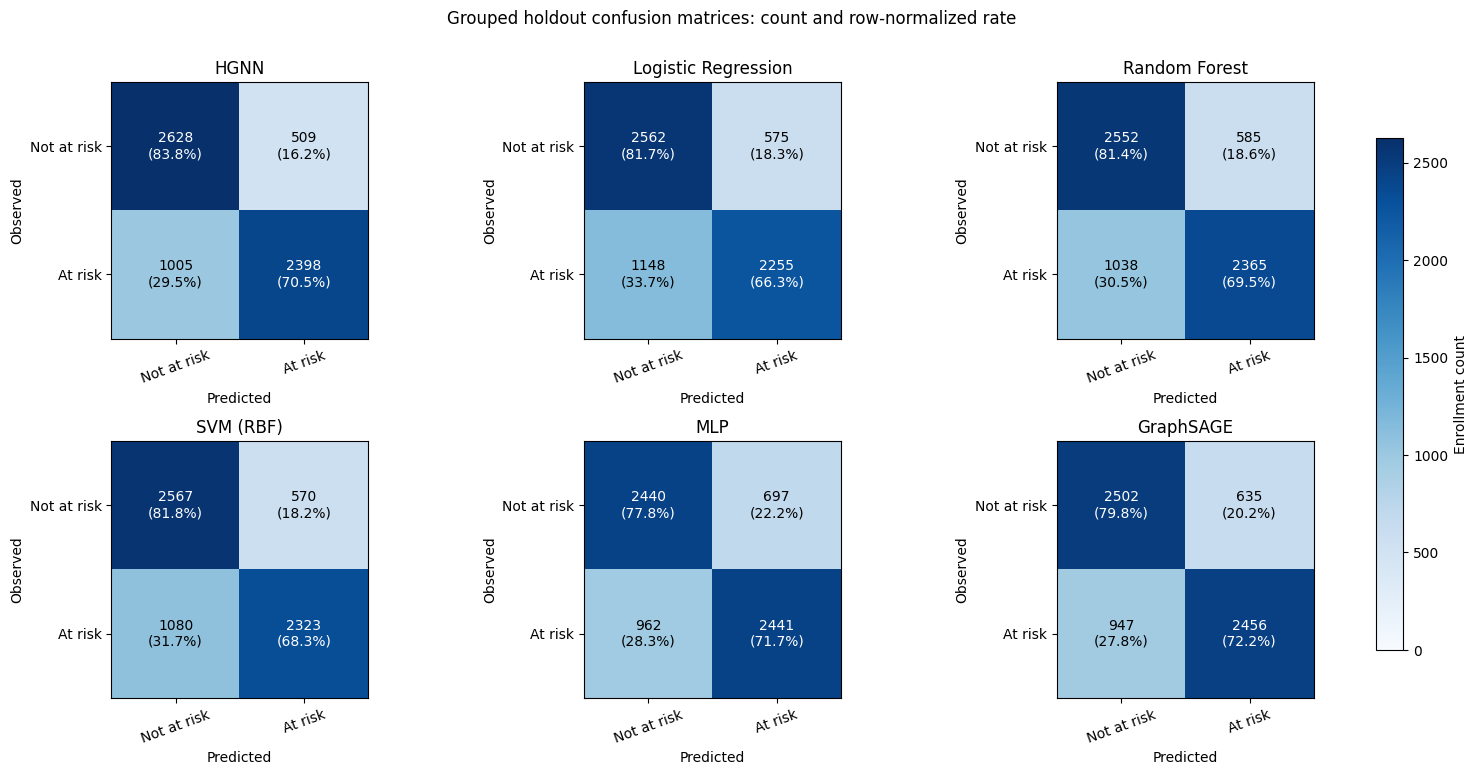

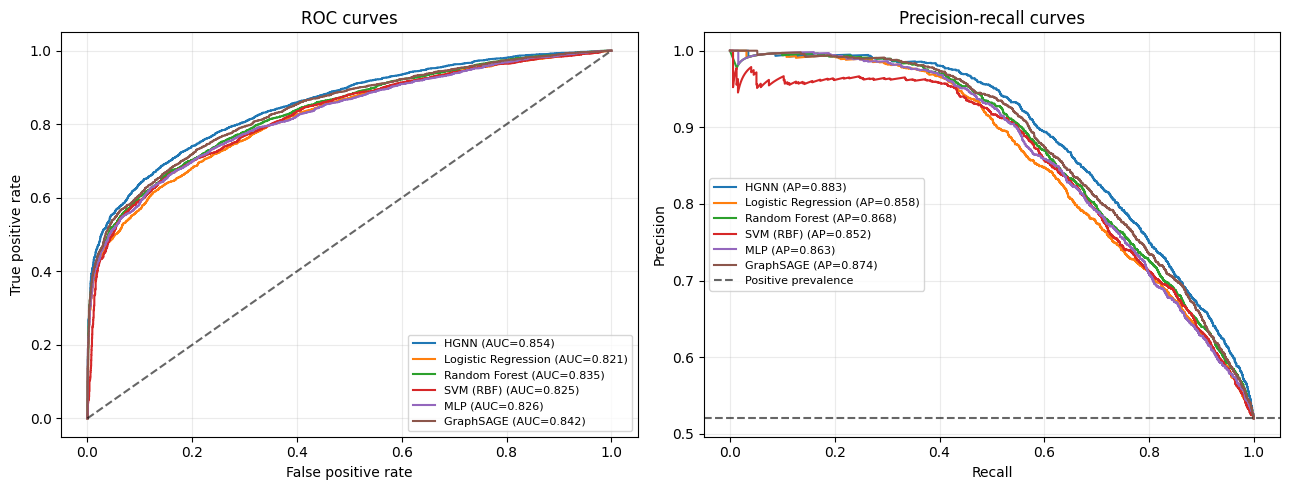

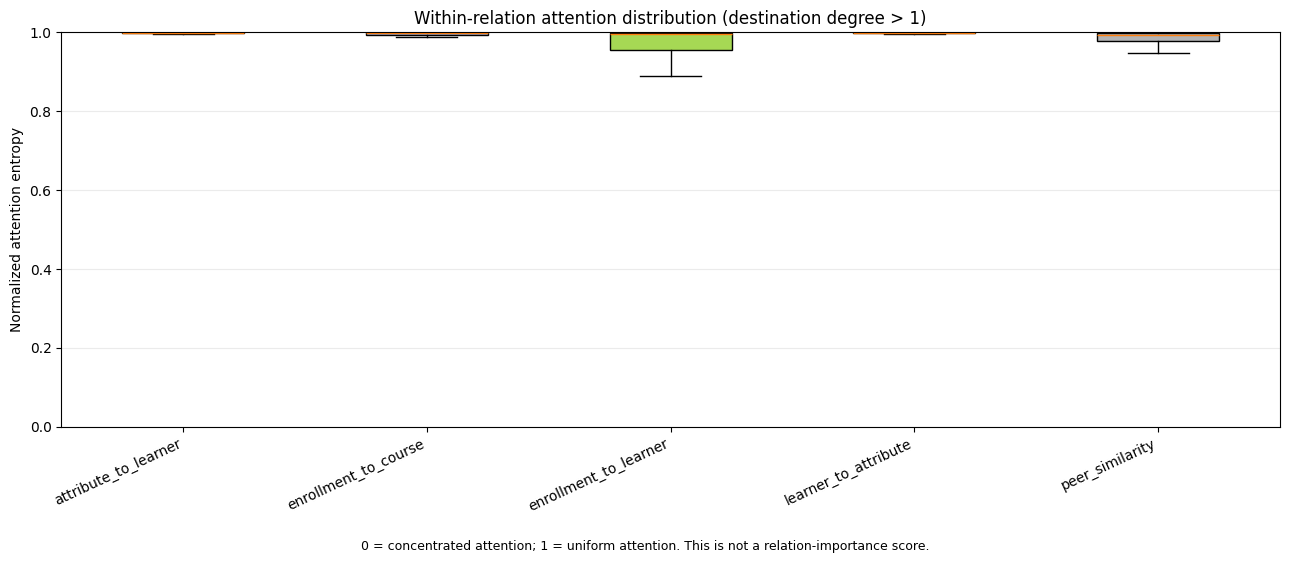

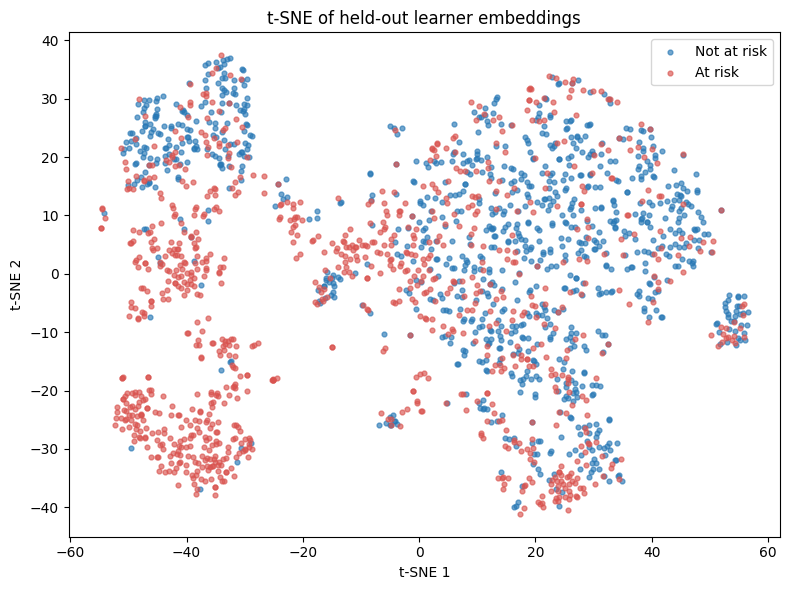

,Ablation,Accuracy,Balanced_accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC,Average Precision (AP)
0,Remove peer similarity,0.7688,0.7715,0.7744,0.7715,0.7685,0.8542,0.8831
1,Remove demographic attributes,0.7694,0.7722,0.7755,0.7722,0.7691,0.8543,0.8835
2,Remove course relations,0.7680,0.7705,0.7727,0.7705,0.7678,0.8543,0.8842


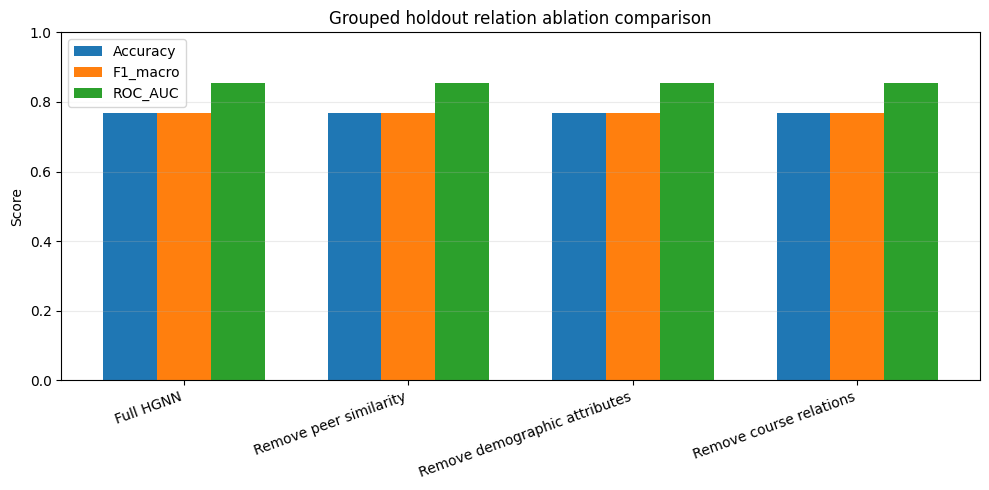

,Candidate_epochs,HGNN_Validation_users,HGNN_Validation_NDCG@5,BPRMF_Validation_users,BPRMF_Validation_NDCG@5
0,20,37,0.7254,37,0.6489
1,40,37,0.6961,37,0.6508
2,60,37,0.6940,37,0.6508


Validation presentation: 2014B | untouched test presentation: 2014J | selected HGNN epochs: 20 | selected BPR-MF epochs: 40

=== PUBLICATION TABLE III: COURSE RECOMMENDATION (CLEAN SINGLE VALUES) ===


,MRR,Recall@1,Precision@1,NDCG@1,Recall@3,Precision@3,NDCG@3,Recall@5,Precision@5,NDCG@5
HGNN (Risk-Aware),0.4986,23.89%,24.0%,0.2400,71.25%,23.85%,0.5038,97.14%,19.53%,0.6121
HGNN,0.5075,24.93%,25.05%,0.2505,72.24%,24.18%,0.5144,97.58%,19.62%,0.6205
BPR-MF,0.4243,16.55%,16.57%,0.1657,54.41%,18.21%,0.3827,88.95%,17.89%,0.5248
Random,0.4155,17.46%,17.5%,0.1750,51.34%,17.2%,0.3665,82.98%,16.7%,0.4958


,Model,Metric,Users,Mean,CI95_low,CI95_high
0,BPR-MF,MRR,861,0.4243,0.4137,0.4353
1,BPR-MF,Recall@1,861,0.1655,0.1512,0.1800
2,BPR-MF,Precision@1,861,0.1657,0.1510,0.1800
3,BPR-MF,NDCG@1,861,0.1657,0.1518,0.1804
4,BPR-MF,Recall@3,861,0.5441,0.5257,0.5633
5,BPR-MF,Precision@3,861,0.1821,0.1756,0.1884
6,BPR-MF,NDCG@3,861,0.3827,0.3678,0.3969
7,BPR-MF,Recall@5,861,0.8895,0.8777,0.9017
8,BPR-MF,Precision@5,861,0.1789,0.1764,0.1816
9,BPR-MF,NDCG@5,861,0.5248,0.5144,0.5356


,Comparator,Metric,Paired_users,HGNN_minus_comparator_mean,CI95_low,CI95_high
0,HGNN (Risk-Aware),MRR,861,0.0089,0.0061,0.0116
1,HGNN (Risk-Aware),Recall@1,861,0.0105,0.0062,0.0151
2,HGNN (Risk-Aware),Precision@1,861,0.0105,0.0062,0.0151
3,HGNN (Risk-Aware),NDCG@1,861,0.0105,0.0062,0.0155
4,HGNN (Risk-Aware),Recall@3,861,0.0099,0.0056,0.0145
5,HGNN (Risk-Aware),Precision@3,861,0.0034,0.0019,0.0049
6,HGNN (Risk-Aware),NDCG@3,861,0.0105,0.0075,0.0138
7,HGNN (Risk-Aware),Recall@5,861,0.0045,0.0021,0.0072
8,HGNN (Risk-Aware),Precision@5,861,0.0009,0.0004,0.0015
9,HGNN (Risk-Aware),NDCG@5,861,0.0084,0.0061,0.0109


Final evaluation: train presentations ['2013B', '2013J', '2014B'] | validation: 2014B | untouched test: 2014J
Eligible users: 861 to 861 | candidate catalog: 7 | scorable catalog: 7


In [8]:
if RUN_HOLDOUT_80_20:
    holdout_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 100)
    train_idx, test_idx = next(holdout_splitter.split(np.zeros(len(base)), y, groups))
    print("Held-out user groups disjoint:", set(groups[train_idx]).isdisjoint(set(groups[test_idx])))
    holdout_seed = SEED + 101
    inner_splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=holdout_seed + 400)
    inner_train_rel, inner_valid_rel = next(inner_splitter.split(
        np.zeros(len(train_idx)), y[train_idx], groups[train_idx]
    ))
    inner_train_idx = train_idx[inner_train_rel]
    inner_valid_idx = train_idx[inner_valid_rel]
    _, inner_train_x, inner_all_x = transform_fold(inner_train_idx)
    inner_graph_x, inner_graph_np, inner_graph_meta = build_graph(base, inner_all_x)
    holdout_tuning_rows, holdout_best_params = [], {}

    # Tune every classifier on the same grouped validation users inside the 80% development partition.
    for model_name in model_names:
        candidate_records = []
        for config_index, params in enumerate(parameter_grids[model_name]):
            if model_name in ("HGNN", "GraphSAGE"):
                candidate_model = (make_hgnn(inner_graph_x.shape[1], seed=holdout_seed)
                                   if model_name == "HGNN" else make_graphsage(inner_graph_x.shape[1], seed=holdout_seed))
                candidate_probability, _, _ = fit_torch_graph_model(
                    candidate_model, inner_graph_x, inner_graph_np, inner_train_idx, y,
                    inner_graph_meta["n_enrollment"], epochs=params.get("epochs", EPOCHS), seed=holdout_seed)
            else:
                candidate_estimator = make_classifier(model_name, params, holdout_seed)
                candidate_probability = fit_baseline_and_predict(
                    model_name, candidate_estimator, inner_train_x, y[inner_train_idx], inner_all_x, holdout_seed)
            validation_ap = classification_metrics(
                y[inner_valid_idx], candidate_probability[inner_valid_idx]
            )["Average Precision (AP)"]
            candidate_records.append((validation_ap, config_index, params))
            holdout_tuning_rows.append({"Model": model_name, "Config": str(params),
                "Inner_validation_AP": validation_ap, "Inner_train_rows": len(inner_train_idx),
                "Inner_validation_rows": len(inner_valid_idx)})
            if model_name in ("HGNN", "GraphSAGE"):
                del candidate_model
            else:
                del candidate_estimator
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        finite = [record for record in candidate_records if np.isfinite(record[0])]
        selected = sorted(finite, key=lambda record: (-record[0], record[1]))[0] if finite else candidate_records[0]
        holdout_best_params[model_name] = selected[2]

    holdout_tuning = pd.DataFrame(holdout_tuning_rows)
    display(holdout_tuning.round(4))
    holdout_tuning.to_csv(OUTPUT_DIR / "grouped_holdout_inner_tuning.csv", index=False)
    del inner_graph_x, inner_graph_np, inner_graph_meta

    # Refit selected configurations on the full 80% development partition; test users remain untouched.
    _, train_x, all_x = transform_fold(train_idx)
    graph_x, graph_np, graph_meta = build_graph(base, all_x)
    holdout_rows, holdout_probabilities = [], {}
    hgnn = make_hgnn(graph_x.shape[1], seed=holdout_seed)
    hgnn_prob, holdout_embeddings, hgnn = fit_torch_graph_model(
        hgnn, graph_x, graph_np, train_idx, y, graph_meta["n_enrollment"],
        epochs=holdout_best_params["HGNN"]["epochs"], seed=holdout_seed
    )
    holdout_probabilities["HGNN"] = hgnn_prob
    holdout_rows.append({"Model": "HGNN", **classification_metrics(y[test_idx], hgnn_prob[test_idx])})
    for model_name in [name for name in model_names if name not in ("HGNN", "GraphSAGE")]:
        estimator = make_classifier(model_name, holdout_best_params[model_name], holdout_seed)
        probability = fit_baseline_and_predict(
            model_name, estimator, train_x, y[train_idx], all_x, holdout_seed)
        holdout_probabilities[model_name] = probability
        holdout_rows.append({"Model": model_name, **classification_metrics(y[test_idx], probability[test_idx])})
        del estimator
    sage = make_graphsage(graph_x.shape[1], seed=holdout_seed)
    sage_prob, _, _ = fit_torch_graph_model(
        sage, graph_x, graph_np, train_idx, y, graph_meta["n_enrollment"],
        epochs=holdout_best_params["GraphSAGE"]["epochs"], seed=holdout_seed
    )
    holdout_probabilities["GraphSAGE"] = sage_prob
    holdout_rows.append({"Model": "GraphSAGE", **classification_metrics(y[test_idx], sage_prob[test_idx])})
    missing_holdout_models = sorted(set(model_names) - set(holdout_probabilities))
    if missing_holdout_models:
        raise RuntimeError(f"Missing grouped-holdout predictions for: {missing_holdout_models}")
    holdout_metrics = pd.DataFrame(holdout_rows)
    display(holdout_metrics.round(4))
    holdout_metrics.to_csv(OUTPUT_DIR / "grouped_holdout_80_20_metrics.csv", index=False)

    # Paired user-cluster bootstrap for balanced accuracy on the untouched grouped holdout.
    # Resample whole users, preserving all of each selected user's held-out rows.
    y_holdout = y[test_idx]
    holdout_group_values = groups[test_idx].astype(str)
    unique_holdout_groups = np.unique(holdout_group_values)
    group_codes = pd.Categorical(holdout_group_values, categories=unique_holdout_groups).codes
    bootstrap_rng = np.random.RandomState(SEED + 333)
    paired_deltas = {name: [] for name in model_names if name != "HGNN"}
    for bootstrap_id in range(200):
        sampled_codes = bootstrap_rng.randint(0, len(unique_holdout_groups), size=len(unique_holdout_groups))
        group_multiplicity = np.bincount(sampled_codes, minlength=len(unique_holdout_groups))
        row_weights = group_multiplicity[group_codes].astype(float)
        active = row_weights > 0
        if len(np.unique(y_holdout[active])) < 2:
            continue
        replicate_scores = {}
        for model_name in model_names:
            probabilities = holdout_probabilities[model_name][test_idx]
            predicted = (probabilities >= 0.5).astype(np.int64)
            replicate_scores[model_name] = balanced_accuracy_score(
                y_holdout, predicted, sample_weight=row_weights
            )
        for model_name in paired_deltas:
            paired_deltas[model_name].append(replicate_scores[model_name] - replicate_scores["HGNN"])
    paired_classification_summary_rows = []
    for model_name, deltas in paired_deltas.items():
        if deltas:
            paired_classification_summary_rows.append({"Comparison": f"{model_name} - HGNN",
                "Metric": "Balanced_accuracy", "Paired_user_bootstrap_replicates": len(deltas),
                "Delta_mean": float(np.mean(deltas)),
                "CI95_low": float(np.quantile(deltas, 0.025)),
                "CI95_high": float(np.quantile(deltas, 0.975))})
    paired_classification_summary = pd.DataFrame(paired_classification_summary_rows)
    display(paired_classification_summary.round(4))
    paired_classification_summary.to_csv(
        OUTPUT_DIR / "grouped_holdout_paired_user_bootstrap_vs_hgnn.csv", index=False
    )

    model_order = list(model_names)  # Keep plots aligned with all fitted classifiers.
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    confusion_matrices = {}
    normalized_matrices = {}
    for model_name in model_order:
        predicted = (holdout_probabilities[model_name][test_idx] >= 0.5).astype(np.int64)
        matrix = confusion_matrix(y[test_idx], predicted, labels=[0, 1])
        row_totals = np.maximum(matrix.sum(axis=1, keepdims=True), 1)
        confusion_matrices[model_name] = matrix
        normalized_matrices[model_name] = matrix / row_totals
    shared_vmax = max(int(matrix.max()) for matrix in confusion_matrices.values())

    for ax, model_name in zip(axes.flat, model_order):
        matrix = confusion_matrices[model_name]
        normalized = normalized_matrices[model_name]
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=shared_vmax)
        ax.set_title(model_name)
        ax.set_xticks([0, 1], ["Not at risk", "At risk"], rotation=20)
        ax.set_yticks([0, 1], ["Not at risk", "At risk"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Observed")
        for row in range(2):
            for col in range(2):
                ax.text(
                    col,
                    row,
                    f"{matrix[row, col]}\n({normalized[row, col]:.1%})",
                    ha="center",
                    va="center",
                    color="white" if matrix[row, col] > shared_vmax * 0.55 else "black",
                )
    # All 6 subplots (including GraphSAGE) are populated; keep axes enabled.
    fig.suptitle("Grouped holdout confusion matrices: count and row-normalized rate")
    # Reserve a dedicated right-side column so the colorbar cannot cover a panel.
    fig.subplots_adjust(left=0.075, right=0.90, bottom=0.12, top=0.89, wspace=0.62, hspace=0.40)
    colorbar_ax = fig.add_axes([0.93, 0.18, 0.018, 0.64])
    fig.colorbar(
        axes.flat[0].images[0],
        cax=colorbar_ax,
        label="Enrollment count",
    )
    fig.savefig(OUTPUT_DIR / "oulad_holdout_confusion_matrices.png", dpi=180, bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for model_name in model_order:
        probability = holdout_probabilities[model_name][test_idx]
        fpr, tpr, _ = roc_curve(y[test_idx], probability)
        axes[0].plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc_score(y[test_idx], probability):.3f})")
        precision_curve, recall_curve, _ = precision_recall_curve(y[test_idx], probability)
        ap = average_precision_score(y[test_idx], probability)
        axes[1].plot(recall_curve, precision_curve, label=f"{model_name} (AP={ap:.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6)
    axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
    axes[1].axhline(float(np.mean(y[test_idx])), color="k", linestyle="--", alpha=0.6, label="Positive prevalence")
    axes[1].set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "oulad_holdout_roc_pr_curves.png", dpi=180, bbox_inches="tight")
    plt.show()

    # Relation-wise normalized attention entropy, excluding degree-one destinations.
    # Degree-one destinations always have alpha=1 and carry no neighbor-choice signal.
    for layer in hgnn.layers:
        layer.capture_attention = True
    attention_x = torch.as_tensor(graph_x, dtype=torch.float32, device=DEVICE)
    attention_edges = relation_edges_to_device(graph_np)
    hgnn.eval()
    with torch.no_grad():
        hgnn(attention_x, attention_edges, graph_meta["n_enrollment"])

    attention_rows = []
    entropy_by_relation = {}
    n_nodes = graph_meta["n_nodes"]
    for layer_number, layer in enumerate(hgnn.layers, start=1):
        for relation, weights in layer.last_attention.items():
            edge_array = graph_np.get(relation)
            if edge_array is None or edge_array.shape[1] == 0:
                continue
            destinations = edge_array[1]
            degree = np.bincount(destinations, minlength=n_nodes)
            eligible_destinations = np.flatnonzero(degree > 1)
            if len(eligible_destinations) == 0:
                continue

            alpha = np.clip(np.asarray(weights, dtype=np.float64), 1e-12, 1.0)
            entropy_by_node = np.zeros((n_nodes, weights.shape[1]), dtype=np.float64)
            np.add.at(entropy_by_node, destinations, -alpha * np.log(alpha))
            normalized_entropy = entropy_by_node[eligible_destinations] / np.log(
                degree[eligible_destinations, None]
            )
            normalized_entropy = np.clip(normalized_entropy, 0.0, 1.0)
            entropy_by_relation.setdefault(relation, []).append(normalized_entropy.reshape(-1))

            for head in range(normalized_entropy.shape[1]):
                values = normalized_entropy[:, head]
                attention_rows.append({
                    "Layer": layer_number,
                    "Relation": relation,
                    "Head": head + 1,
                    "Mean_normalized_entropy": float(np.mean(values)),
                    "Median_normalized_entropy": float(np.median(values)),
                    "P95_normalized_entropy": float(np.quantile(values, 0.95)),
                    "Destinations_with_degree_greater_than_one": int(len(eligible_destinations)),
                })

    attention_summary = pd.DataFrame(attention_rows)
    attention_summary.to_csv(OUTPUT_DIR / "oulad_hgnn_relation_attention_summary.csv", index=False)
    relation_names = sorted(entropy_by_relation)
    if relation_names:
        fig, ax = plt.subplots(figsize=(13, 6))
        box_data = [np.concatenate(entropy_by_relation[name]) for name in relation_names]
        boxplot = ax.boxplot(box_data, showfliers=False, patch_artist=True)
        colors = plt.cm.Set2(np.linspace(0, 1, len(relation_names)))
        for box, color in zip(boxplot["boxes"], colors):
            box.set_facecolor(color)
        ax.set_xticks(range(1, len(relation_names) + 1), relation_names, rotation=25, ha="right")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Normalized attention entropy")
        ax.set_title("Within-relation attention distribution (destination degree > 1)")
        ax.grid(axis="y", alpha=0.25)
        fig.text(
            0.5,
            0.02,
            "0 = concentrated attention; 1 = uniform attention. This is not a relation-importance score.",
            ha="center",
            va="bottom",
            fontsize=9,
        )
        fig.tight_layout(rect=[0, 0.06, 1, 0.95])
        fig.savefig(OUTPUT_DIR / "oulad_hgnn_relation_attention.png", dpi=180, bbox_inches="tight")
        plt.show()
    else:
        print("Attention entropy plot skipped: no relation has destinations with multiple incoming neighbors.")

    # t-SNE view of held-out learner embeddings; color denotes any at-risk held-out enrollment.
    id_to_learner_position = {
        str(learner_id): pos for pos, learner_id in enumerate(graph_meta["learner_values"])
    }
    test_learner_labels = (
        base.iloc[test_idx].assign(id_student=base.iloc[test_idx]["id_student"].astype(str))
        .groupby("id_student")["At_Risk"].max()
    )
    plot_ids = []
    plot_labels = []
    rng = np.random.RandomState(SEED)
    for label in [0, 1]:
        ids = [str(learner_id) for learner_id, value in test_learner_labels.items()
               if int(value) == label and str(learner_id) in id_to_learner_position]
        take = min(1000, len(ids))
        if take:
            plot_ids.extend(rng.choice(ids, size=take, replace=False).tolist())
            plot_labels.extend([label] * take)
    if len(plot_ids) >= 4:
        learner_node_x = holdout_embeddings[graph_meta["learner_offset"]:graph_meta["course_offset"]]
        tsne_input = np.stack([
            learner_node_x[id_to_learner_position[learner_id]] for learner_id in plot_ids
        ])
        perplexity = min(30.0, max(2.0, (len(plot_ids) - 1) / 3.0))
        tsne_xy = TSNE(n_components=2, random_state=SEED, init="pca", learning_rate="auto",
                       perplexity=perplexity).fit_transform(tsne_input)
        fig, ax = plt.subplots(figsize=(8, 6))
        for label, label_text, color in [(0, "Not at risk", "#2878B5"), (1, "At risk", "#D9534F")]:
            mask = np.asarray(plot_labels) == label
            ax.scatter(tsne_xy[mask, 0], tsne_xy[mask, 1], s=12, alpha=0.65, label=label_text, c=color)
        ax.set_title("t-SNE of held-out learner embeddings")
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "oulad_holdout_learner_embeddings_tsne.png", dpi=180, bbox_inches="tight")
        plt.show()
    else:
        print("Skipped t-SNE: fewer than four held-out learners available.")

    if RUN_ABLATIONS:
        ablation_groups = {
            "Remove peer similarity": {"peer_similarity"},
            "Remove demographic attributes": {"learner_to_attribute", "attribute_to_learner"},
            "Remove course relations": {"enrollment_to_course", "course_to_enrollment"},
        }
        ablation_rows = []
        for ablation_name, removed in ablation_groups.items():
            active = [r for r in RELATION_NAMES if r not in removed]
            ablated = make_hgnn(graph_x.shape[1], seed=SEED + 101)
            p, _, _ = fit_torch_graph_model(
                ablated, graph_x, graph_np, train_idx, y, graph_meta["n_enrollment"],
                active_relations=active, epochs=holdout_best_params["HGNN"]["epochs"], seed=holdout_seed,
            )
            ablation_rows.append({"Ablation": ablation_name, **classification_metrics(y[test_idx], p[test_idx])})
        ablation_metrics = pd.DataFrame(ablation_rows)
        display(ablation_metrics.round(4))
        ablation_metrics.to_csv(OUTPUT_DIR / "oulad_holdout_ablation_metrics.csv", index=False)
        full_hgnn_row = holdout_metrics.loc[holdout_metrics["Model"] == "HGNN"].iloc[0]
        ablation_plot = pd.concat([
            pd.DataFrame([{"Ablation": "Full HGNN", **{m: full_hgnn_row[m] for m in ["Accuracy", "F1_macro", "ROC_AUC"]}}]),
            ablation_metrics[["Ablation", "Accuracy", "F1_macro", "ROC_AUC"]],
        ], ignore_index=True)
        fig, ax = plt.subplots(figsize=(10, 5))
        x = np.arange(len(ablation_plot))
        width = 0.24
        for offset, metric in enumerate(["Accuracy", "F1_macro", "ROC_AUC"]):
            ax.bar(x + (offset - 1) * width, ablation_plot[metric], width, label=metric)
        ax.set_xticks(x, ablation_plot["Ablation"], rotation=20, ha="right")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Score")
        ax.set_title("Grouped holdout relation ablation comparison")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "oulad_holdout_ablation_comparison.png", dpi=180, bbox_inches="tight")
        plt.show()

    # Temporal next-module ranking: validation selects epochs; the latest presentation is untouched test.
    def presentation_order(value):
        value = str(value)
        year = int(value[:4])
        suffix = value[4:]
        period_order = {"B": 0, "J": 1}.get(suffix, 2)
        return year, period_order, suffix

    ordered_presentations = sorted(base["code_presentation"].astype(str).unique(), key=presentation_order)
    if len(ordered_presentations) < 3:
        raise ValueError("Temporal tuning requires at least three presentations: train, validation, and test.")
    target_presentation = ordered_presentations[-1]
    validation_presentation = ordered_presentations[-2]
    rank_tune_train = base.loc[~base["code_presentation"].astype(str).isin(
        [validation_presentation, target_presentation])].copy().reset_index(drop=True)
    rank_validation = base.loc[base["code_presentation"].astype(str).eq(validation_presentation)].copy()
    rank_history = base.loc[base["code_presentation"].astype(str).ne(target_presentation)].copy().reset_index(drop=True)
    rank_future = base.loc[base["code_presentation"].astype(str).eq(target_presentation)].copy()
    if rank_tune_train.empty or rank_history.empty:
        raise ValueError("OULAD temporal ranking needs at least two training presentations.")

    def fit_oulad_temporal_graph(train_frame, fit_seed, epochs):
        prep = make_preprocessor()
        feat = dense_float32(prep.fit_transform(train_frame[FEATURE_COLS]))
        graph_x_local, graph_edges_local, graph_meta_local = build_graph(train_frame, feat)
        learner_ids_local = [str(v) for v in graph_meta_local["learner_values"]]
        course_keys_local = [str(v) for v in graph_meta_local["course_values"]]
        learner_index_local = {u: graph_meta_local["learner_offset"] + i for i, u in enumerate(learner_ids_local)}
        course_index_local = {key: graph_meta_local["course_offset"] + i for i, key in enumerate(course_keys_local)}
        positive_by_user = {}
        for row in train_frame[["id_student", "code_module", "code_presentation"]].itertuples(index=False):
            positive_by_user.setdefault(str(row.id_student), set()).add(
                f"{row.code_module}::{row.code_presentation}"
            )
        pair_rng = np.random.RandomState(fit_seed)
        user_pair_idx, positive_pair_idx, negative_pair_idx = [], [], []
        all_courses = set(course_index_local)
        for learner_id in sorted(positive_by_user):
            if learner_id not in learner_index_local:
                continue
            positives = positive_by_user[learner_id] & all_courses
            prior_modules = {key.split("::", 1)[0] for key in positives}
            # Sample a course-module not previously taken by this learner; no future interactions are used.
            negatives = [key for key in course_keys_local if key.split("::", 1)[0] not in prior_modules]
            if not positives or not negatives:
                continue
            negative_order = sorted(negatives)
            for positive_course in sorted(positives):
                negative_course = negative_order[pair_rng.randint(len(negative_order))]
                user_pair_idx.append(learner_index_local[learner_id])
                positive_pair_idx.append(course_index_local[positive_course])
                negative_pair_idx.append(course_index_local[negative_course])
        if not user_pair_idx:
            raise ValueError("No valid OULAD learner-positive-negative course triples; check presentations and learner history.")
        if len(user_pair_idx) > MAX_PAIRWISE_TRAIN_PAIRS:
            chosen = pair_rng.choice(len(user_pair_idx), MAX_PAIRWISE_TRAIN_PAIRS, replace=False)
            user_pair_idx = np.asarray(user_pair_idx, dtype=np.int64)[chosen]
            positive_pair_idx = np.asarray(positive_pair_idx, dtype=np.int64)[chosen]
            negative_pair_idx = np.asarray(negative_pair_idx, dtype=np.int64)[chosen]
        else:
            user_pair_idx = np.asarray(user_pair_idx, dtype=np.int64)
            positive_pair_idx = np.asarray(positive_pair_idx, dtype=np.int64)
            negative_pair_idx = np.asarray(negative_pair_idx, dtype=np.int64)
        x_tensor = torch.as_tensor(graph_x_local, dtype=torch.float32, device=DEVICE)
        edge_tensor = relation_edges_to_device(graph_edges_local)
        user_tensor = torch.as_tensor(user_pair_idx, dtype=torch.long, device=DEVICE)
        pos_tensor = torch.as_tensor(positive_pair_idx, dtype=torch.long, device=DEVICE)
        neg_tensor = torch.as_tensor(negative_pair_idx, dtype=torch.long, device=DEVICE)
        model_local = make_hgnn(graph_x_local.shape[1], seed=fit_seed).to(DEVICE)
        optimizer = torch.optim.Adam(model_local.parameters(), lr=0.001, weight_decay=1e-4)
        for _ in range(epochs):
            model_local.train()
            optimizer.zero_grad(set_to_none=True)
            _, z = model_local(x_tensor, edge_tensor, graph_meta_local["n_enrollment"])
            user_z = F.normalize(z[user_tensor], p=2, dim=1)
            pos_z = F.normalize(z[pos_tensor], p=2, dim=1)
            neg_z = F.normalize(z[neg_tensor], p=2, dim=1)
            margin = (user_z * pos_z).sum(dim=1) - (user_z * neg_z).sum(dim=1)
            regularizer = (user_z.square().sum() + pos_z.square().sum() + neg_z.square().sum()) / max(1, len(user_pair_idx))
            loss = F.softplus(-margin).mean() + 1e-5 * regularizer
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_local.parameters(), max_norm=5.0)
            optimizer.step()
        model_local.eval()
        with torch.no_grad():
            _, emb_local = model_local(x_tensor, edge_tensor, graph_meta_local["n_enrollment"])
            emb_local = emb_local.detach().cpu().numpy()
        learner_vectors_local = emb_local[
            graph_meta_local["learner_offset"]:graph_meta_local["learner_offset"] + len(learner_ids_local)
        ]
        norms = np.maximum(np.linalg.norm(learner_vectors_local, axis=1, keepdims=True), 1e-12)
        learner_map_local = {u: learner_vectors_local[i] / norms[i, 0] for i, u in enumerate(learner_ids_local)}
        course_vectors = emb_local[
            graph_meta_local["course_offset"]:graph_meta_local["course_offset"] + len(course_keys_local)
        ]
        module_rows = {}
        for idx, key in enumerate(course_keys_local):
            module = key.split("::", 1)[0]
            module_rows.setdefault(module, []).append(course_vectors[idx])
        module_map_local = {module: np.mean(np.stack(vectors), axis=0) for module, vectors in module_rows.items()}
        module_map_local = {module: vec / max(float(np.linalg.norm(vec)), 1e-12)
                            for module, vec in module_map_local.items()}
        return learner_map_local, module_map_local

    def fit_oulad_bpr_mf(train_frame, fit_seed, epochs):
        """BPR matrix factorization on the same historical learner-course triples as the HGNN."""
        learner_ids_local = sorted(train_frame["id_student"].astype(str).unique().tolist())
        course_key = train_frame["code_module"].astype(str) + "::" + train_frame["code_presentation"].astype(str)
        course_keys_local = sorted(course_key.unique().tolist())
        learner_index_local = {value: idx for idx, value in enumerate(learner_ids_local)}
        course_index_local = {value: idx for idx, value in enumerate(course_keys_local)}
        positive_by_user = {}
        for row in train_frame[["id_student", "code_module", "code_presentation"]].itertuples(index=False):
            positive_by_user.setdefault(str(row.id_student), set()).add(f"{row.code_module}::{row.code_presentation}")
        pair_rng = np.random.RandomState(fit_seed)
        user_pair_idx, positive_pair_idx, negative_pair_idx = [], [], []
        all_courses = set(course_keys_local)
        for learner_id in sorted(positive_by_user):
            positives = positive_by_user[learner_id] & all_courses
            prior_modules = {key.split("::", 1)[0] for key in positives}
            negatives = [key for key in course_keys_local if key.split("::", 1)[0] not in prior_modules]
            if not positives or not negatives:
                continue
            for positive_course in sorted(positives):
                user_pair_idx.append(learner_index_local[learner_id])
                positive_pair_idx.append(course_index_local[positive_course])
                negative_pair_idx.append(course_index_local[negatives[pair_rng.randint(len(negatives))]])
        if not user_pair_idx:
            raise ValueError("BPR-MF could not form historical learner-positive-negative course triples.")
        if len(user_pair_idx) > MAX_PAIRWISE_TRAIN_PAIRS:
            chosen = pair_rng.choice(len(user_pair_idx), MAX_PAIRWISE_TRAIN_PAIRS, replace=False)
            user_pair_idx = np.asarray(user_pair_idx, dtype=np.int64)[chosen]
            positive_pair_idx = np.asarray(positive_pair_idx, dtype=np.int64)[chosen]
            negative_pair_idx = np.asarray(negative_pair_idx, dtype=np.int64)[chosen]
        else:
            user_pair_idx = np.asarray(user_pair_idx, dtype=np.int64)
            positive_pair_idx = np.asarray(positive_pair_idx, dtype=np.int64)
            negative_pair_idx = np.asarray(negative_pair_idx, dtype=np.int64)
        torch.manual_seed(fit_seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(fit_seed)
        user_factors = nn.Embedding(len(learner_ids_local), HIDDEN_DIM).to(DEVICE)
        course_factors = nn.Embedding(len(course_keys_local), HIDDEN_DIM).to(DEVICE)
        nn.init.normal_(user_factors.weight, std=0.05)
        nn.init.normal_(course_factors.weight, std=0.05)
        optimizer = torch.optim.Adam(list(user_factors.parameters()) + list(course_factors.parameters()), lr=0.01)
        user_tensor = torch.as_tensor(user_pair_idx, dtype=torch.long, device=DEVICE)
        pos_tensor = torch.as_tensor(positive_pair_idx, dtype=torch.long, device=DEVICE)
        neg_tensor = torch.as_tensor(negative_pair_idx, dtype=torch.long, device=DEVICE)
        for _ in range(epochs):
            optimizer.zero_grad(set_to_none=True)
            user_vec = user_factors(user_tensor)
            pos_vec = course_factors(pos_tensor)
            neg_vec = course_factors(neg_tensor)
            margin = (user_vec * pos_vec).sum(dim=1) - (user_vec * neg_vec).sum(dim=1)
            reg = (user_vec.square().sum() + pos_vec.square().sum() + neg_vec.square().sum()) / max(1, len(user_pair_idx))
            loss = F.softplus(-margin).mean() + 1e-5 * reg
            loss.backward()
            torch.nn.utils.clip_grad_norm_(list(user_factors.parameters()) + list(course_factors.parameters()), 5.0)
            optimizer.step()
        with torch.no_grad():
            learner_vectors = F.normalize(user_factors.weight, p=2, dim=1).cpu().numpy()
            course_vectors = course_factors.weight.detach().cpu().numpy()
        learner_map_local = {value: learner_vectors[idx] for idx, value in enumerate(learner_ids_local)}
        module_rows = {}
        for idx, key in enumerate(course_keys_local):
            module = key.split("::", 1)[0]
            module_rows.setdefault(module, []).append(course_vectors[idx])
        module_map_local = {module: np.mean(np.stack(vectors), axis=0) for module, vectors in module_rows.items()}
        module_map_local = {module: vec / max(float(np.linalg.norm(vec)), 1e-12)
                            for module, vec in module_map_local.items()}
        return learner_map_local, module_map_local

    def score_oulad_window(train_frame, target_frame, user_vectors, module_vectors,
                           bpr_user_vectors, bpr_module_vectors, seed):
        candidate_catalog = set(target_frame["code_module"].astype(str).unique())
        scorable_catalog = candidate_catalog & set(module_vectors)
        history_modules = train_frame.groupby(train_frame["id_student"].astype(str))["code_module"].apply(
            lambda values: set(values.astype(str))).to_dict()
        target_modules = target_frame.groupby(target_frame["id_student"].astype(str))["code_module"].apply(
            lambda values: set(values.astype(str))).to_dict()
        future_users_with_history = sum(u in history_modules for u in target_modules)
        user_rows, top_rows = [], []
        coverage = {name: set() for name in ["HGNN", "HGNN (Risk-Aware)", "BPR-MF", "Random"]}
        rng_local = np.random.RandomState(seed)
        hist_course_risk = train_frame.groupby("code_module")["At_Risk"].mean().to_dict()
        hist_learner_risk = train_frame.groupby("id_student")["At_Risk"].mean().to_dict()

        for learner_id in sorted(target_modules):
            if learner_id not in user_vectors:
                continue
            prior_modules = history_modules.get(learner_id, set())
            relevant = (target_modules[learner_id] - prior_modules) & scorable_catalog
            candidates = sorted(module for module in scorable_catalog if module not in prior_modules)
            if not relevant or not candidates:
                continue
            u_risk = hist_learner_risk.get(learner_id, 0.5)
            hgnn_scores = np.asarray([np.dot(user_vectors[learner_id], module_vectors[m]) for m in candidates])
            # Novel Pedagogically-Constrained Risk-Aware Ranking:
            risk_aware_scores = np.asarray([
                np.dot(user_vectors[learner_id], module_vectors[m]) - (RISK_AWARE_LAMBDA * hist_course_risk.get(m, 0.5) * u_risk)
                for m in candidates
            ])
            bprmf_scores = np.asarray([np.dot(bpr_user_vectors[learner_id], bpr_module_vectors[m]) for m in candidates])
            random_scores = rng_local.random_sample(len(candidates))
            for model_name, scores in {
                "HGNN": hgnn_scores,
                "HGNN (Risk-Aware)": risk_aware_scores,
                "BPR-MF": bprmf_scores,
                "Random": random_scores,
            }.items():
                order = np.lexsort((np.asarray(candidates, dtype=str), -scores))
                ranked = [candidates[j] for j in order]
                coverage[model_name].update(ranked[:5])
                first_hit = next((rank for rank, m in enumerate(ranked, 1) if m in relevant), None)
                metric = {"Seed": seed, "Model": model_name, "User_ID": learner_id,
                          "MRR": 0.0 if first_hit is None else 1.0 / first_hit}
                for k in RANKING_KS:
                    top_k = ranked[:k]
                    hits = sum(m in relevant for m in top_k)
                    metric[f"Recall@{k}"] = hits / max(1, len(relevant))
                    metric[f"Precision@{k}"] = hits / max(1, len(top_k))
                    dcg = sum(1.0 / np.log2(rank + 1) for rank, m in enumerate(top_k, 1) if m in relevant)
                    idcg = sum(1.0 / np.log2(rank + 1) for rank in range(1, min(len(relevant), k) + 1))
                    metric[f"NDCG@{k}"] = dcg / idcg if idcg else 0.0
                user_rows.append(metric)
                for rank, module in enumerate(ranked[:5], 1):
                    top_rows.append({"Seed": seed, "Model": model_name, "Student_ID": learner_id,
                        "Target_Presentation": str(target_frame["code_presentation"].iloc[0]),
                        "Rank": rank, "Recommended_Module": module, "Relevant": int(module in relevant)})
        catalog_rows = [{"Seed": seed, "Model": name, "Eligible_users": len({r["User_ID"] for r in user_rows if r["Model"] == name}),
                         "Future_users_with_history": future_users_with_history,
                         "Candidate_catalog_size": len(candidate_catalog), "Scorable_catalog_size": len(scorable_catalog),
                         "Future_new_course_coverage": len(scorable_catalog) / max(1, len(candidate_catalog)),
                         "Catalog_coverage@5": len(items) / max(1, len(candidate_catalog))}
                        for name, items in coverage.items()]
        return pd.DataFrame(user_rows), pd.DataFrame(top_rows), pd.DataFrame(catalog_rows)

    # Tune HGNN and BPR-MF epoch counts on the penultimate presentation only.
    validation_tuning_rows = []
    for candidate_epochs in RANKING_EPOCH_CANDIDATES:
        val_users_hgnn, val_modules_hgnn = fit_oulad_temporal_graph(rank_tune_train, SEED + 700, candidate_epochs)
        val_users_mf, val_modules_mf = fit_oulad_bpr_mf(rank_tune_train, SEED + 700, candidate_epochs)
        val_metrics, _, _ = score_oulad_window(
            rank_tune_train, rank_validation, val_users_hgnn, val_modules_hgnn,
            val_users_mf, val_modules_mf, SEED + 700
        )
        hgnn_values = val_metrics.loc[val_metrics["Model"].eq("HGNN"), "NDCG@5"]
        mf_values = val_metrics.loc[val_metrics["Model"].eq("BPR-MF"), "NDCG@5"]
        validation_tuning_rows.append({
            "Candidate_epochs": candidate_epochs,
            "HGNN_Validation_users": int(hgnn_values.size),
            "HGNN_Validation_NDCG@5": float(hgnn_values.mean()) if len(hgnn_values) else np.nan,
            "BPRMF_Validation_users": int(mf_values.size),
            "BPRMF_Validation_NDCG@5": float(mf_values.mean()) if len(mf_values) else np.nan,
        })
        del val_users_hgnn, val_modules_hgnn, val_users_mf, val_modules_mf
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    validation_tuning = pd.DataFrame(validation_tuning_rows)

    def _select_oulad_epochs(metric_column):
        valid = validation_tuning.dropna(subset=[metric_column])
        if valid.empty:
            print(f"WARNING: no validation scores for {metric_column}; using EPOCHS={EPOCHS}.")
            return EPOCHS
        return int(valid.sort_values([metric_column, "Candidate_epochs"], ascending=[False, True]).iloc[0]["Candidate_epochs"])

    selected_hgnn_epochs = _select_oulad_epochs("HGNN_Validation_NDCG@5")
    selected_bprmf_epochs = _select_oulad_epochs("BPRMF_Validation_NDCG@5")
    display(validation_tuning.round(4))
    print("Validation presentation:", validation_presentation, "| untouched test presentation:", target_presentation,
          "| selected HGNN epochs:", selected_hgnn_epochs, "| selected BPR-MF epochs:", selected_bprmf_epochs)
    validation_tuning.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_validation_tuning.csv", index=False)

    user_metric_frames, top5_frames, catalog_frames = [], [], []
    for ranking_seed in RANKING_SEEDS:
        user_vectors, module_vectors = fit_oulad_temporal_graph(rank_history, ranking_seed, selected_hgnn_epochs)
        bpr_user_vectors, bpr_module_vectors = fit_oulad_bpr_mf(rank_history, ranking_seed, selected_bprmf_epochs)
        user_metrics_seed, top5_seed, catalog_seed = score_oulad_window(
            rank_history, rank_future, user_vectors, module_vectors,
            bpr_user_vectors, bpr_module_vectors, ranking_seed
        )
        user_metric_frames.append(user_metrics_seed)
        top5_frames.append(top5_seed)
        catalog_frames.append(catalog_seed)
        del user_vectors, module_vectors, bpr_user_vectors, bpr_module_vectors
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    temporal_user_metrics = pd.concat(user_metric_frames, ignore_index=True)
    if temporal_user_metrics.empty:
        raise ValueError("No final-presentation learners have new scorable modules. Report this limitation; do not report empty ranking metrics.")
    temporal_top5 = pd.concat(top5_frames, ignore_index=True)
    temporal_catalog = pd.concat(catalog_frames, ignore_index=True).drop_duplicates(["Seed", "Model"])
    ranking_metric_cols = ["MRR"] + [f"{metric}@{k}" for k in RANKING_KS for metric in ["Recall", "Precision", "NDCG"]]
    temporal_ranking_by_seed_model = temporal_user_metrics.groupby(["Seed", "Model"])[ranking_metric_cols].mean().reset_index()
    temporal_ranking_by_seed_model = temporal_ranking_by_seed_model.merge(temporal_catalog, on=["Seed", "Model"], how="left")
    temporal_ranking_summary = temporal_ranking_by_seed_model.groupby("Model")[ranking_metric_cols + [
        "Eligible_users", "Future_users_with_history", "Candidate_catalog_size", "Scorable_catalog_size",
        "Future_new_course_coverage", "Catalog_coverage@5"]].agg(["mean", "std"])
    temporal_ranking_by_seed_model.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_metrics_by_seed_model.csv", index=False)
    temporal_ranking_summary.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_metrics_summary.csv")

    # Single clean value publication table for Course Recommendation
    rec_models_order = [m for m in ["HGNN (Risk-Aware)", "HGNN", "BPR-MF", "Random"] if m in temporal_user_metrics["Model"].unique()]
    rec_single = temporal_user_metrics.groupby("Model")[ranking_metric_cols].mean()
    pub_ranking = pd.DataFrame(index=rec_models_order)
    for col in ranking_metric_cols:
        if any(term in col for term in ["Recall", "Precision", "Safe_Rec_Rate"]):
            pub_ranking[col] = (rec_single.loc[rec_models_order, col] * 100).round(2).astype(str) + "%"
        else:
            pub_ranking[col] = rec_single.loc[rec_models_order, col].round(4)

    print("\n" + "="*70)
    print("=== PUBLICATION TABLE III: COURSE RECOMMENDATION (CLEAN SINGLE VALUES) ===")
    print("="*70)
    display(pub_ranking)
    pub_ranking.to_csv(OUTPUT_DIR / "publication_table_III_recommendation_single_values.csv")
    temporal_user_metrics.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_user_metrics.csv", index=False)
    temporal_top5.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_top5_by_user_model.csv", index=False)

    # User-level bootstrap intervals summarize each ranker over its own final-test users.
    metric_user_mean = temporal_user_metrics.groupby(["Model", "User_ID"])[ranking_metric_cols].mean().reset_index()
    bootstrap_rng = np.random.RandomState(SEED + 900)
    bootstrap_rows = []
    for model_name in sorted(metric_user_mean["Model"].unique()):
        frame = metric_user_mean.loc[metric_user_mean["Model"].eq(model_name)]
        for metric_name in ranking_metric_cols:
            vals = frame[metric_name].dropna().to_numpy(dtype=float)
            if len(vals):
                boot = np.asarray([bootstrap_rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(2000)])
                bootstrap_rows.append({"Model": model_name, "Metric": metric_name, "Users": len(vals),
                    "Mean": float(vals.mean()), "CI95_low": float(np.quantile(boot, .025)),
                    "CI95_high": float(np.quantile(boot, .975))})
    ranking_user_bootstrap_ci = pd.DataFrame(bootstrap_rows)
    display(ranking_user_bootstrap_ci.round(4))
    ranking_user_bootstrap_ci.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_user_bootstrap_ci.csv", index=False)
    paired_ranking_rows = []
    paired_rng = np.random.RandomState(SEED + 901)
    for comparator in ["HGNN (Risk-Aware)", "BPR-MF", "Random"]:
        for metric_name in ranking_metric_cols:
            wide = metric_user_mean.pivot(index="User_ID", columns="Model", values=metric_name).dropna(
                subset=["HGNN", comparator]
            )
            delta = (wide["HGNN"] - wide[comparator]).to_numpy(dtype=float)
            if len(delta):
                boot = np.asarray([paired_rng.choice(delta, size=len(delta), replace=True).mean()
                                   for _ in range(2000)])
                paired_ranking_rows.append({"Comparator": comparator, "Metric": metric_name,
                    "Paired_users": len(delta), "HGNN_minus_comparator_mean": float(delta.mean()),
                    "CI95_low": float(np.quantile(boot, 0.025)), "CI95_high": float(np.quantile(boot, 0.975))})
    paired_ranking_summary = pd.DataFrame(paired_ranking_rows)
    display(paired_ranking_summary.round(4))
    paired_ranking_summary.to_csv(OUTPUT_DIR / "oulad_temporal_ranking_paired_hgnn_vs_baselines.csv", index=False)
    if temporal_ranking_by_seed_model["Eligible_users"].min() < 30 or temporal_ranking_by_seed_model["Candidate_catalog_size"].max() < 20:
        print("WARNING: the target catalog is small and/or fewer than 30 users are eligible; do not generalize this ranking score.")
    print("Final evaluation: train presentations", ordered_presentations[:-1], "| validation:", validation_presentation,
          "| untouched test:", target_presentation)
    print("Eligible users:", int(temporal_ranking_by_seed_model["Eligible_users"].min()), "to",
          int(temporal_ranking_by_seed_model["Eligible_users"].max()), "| candidate catalog:",
          int(temporal_ranking_by_seed_model["Candidate_catalog_size"].max()), "| scorable catalog:",
          int(temporal_ranking_by_seed_model["Scorable_catalog_size"].max()))

else:
    raise RuntimeError("RUN_HOLDOUT_80_20 must remain True for this notebook.")


## Paper Figures & Statistical Tables (Figs. 3, 4, 5, 7, 8, 9 & Tables III, V, VIII)

The cells below generate the publication figures and supplementary evaluation tables reported in the paper directly from the in-memory results (or from the CSV files saved in `OUTPUT_DIR`):
- **Table III & Fig. 5:** Pooled out-of-fold ROC, Precision–Recall, and decile Calibration curves (plus Brier score and ECE).
- **Table V & Fig. 3:** Outer-fold balanced accuracy distributions and paired learner-cluster bootstrap confidence intervals (1,000 CV out-of-fold replicates + 200 grouped-holdout replicates).
- **Fig. 4:** Module-by-presentation at-risk heatmap and subgroup balanced accuracy breakdowns.
- **Fig. 7:** Holdout relation-ablation deltas in percentage points with the `±0.1 pp` band.
- **Fig. 8:** Temporal `2014J` curriculum recommendation Recall@K and MRR (with per-seed points and 95% CIs).
- **Table VIII & Fig. 9:** Safety analysis of Rank-1 recommended module failure rates across historical risk groups (`ρ_u ≥ 0.5` vs `ρ_u < 0.5`) and module redistribution.


=== TABLE III: PROBABILITY QUALITY (POOLED OOF, MEAN OVER SEEDS) ===


,Model,ROC-AUC,AP,Brier,ECE
0,HGNN,0.8556,0.8874,0.1535,0.0245
1,GraphSAGE,0.8429,0.8769,0.1605,0.0273
2,Random Forest,0.8392,0.8748,0.1615,0.0153
3,MLP,0.8331,0.8698,0.1655,0.0348
4,SVM (RBF),0.8302,0.8587,0.1661,0.0278
5,Logistic Regression,0.8290,0.8657,0.1666,0.0185


=== TABLE V: PAIRED LEARNER-LEVEL BOOTSTRAP ON CV OOF (1,000 REPLICATES) ===


,Baseline Comparison,Delta_mean,CI95_low,CI95_high
0,Logistic Regression vs. HGNN,-0.0232,-0.0267,-0.0199
1,Random Forest vs. HGNN,-0.0135,-0.0164,-0.0108
2,SVM (RBF) vs. HGNN,-0.0161,-0.0191,-0.0134
3,MLP vs. HGNN,-0.0197,-0.0225,-0.0169
4,GraphSAGE vs. HGNN,-0.0114,-0.0136,-0.0092


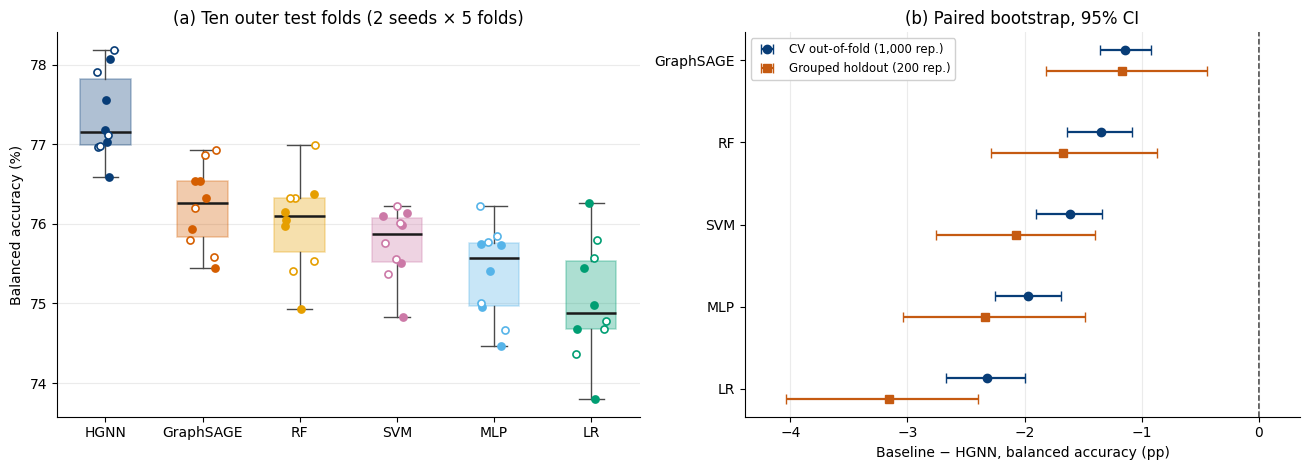

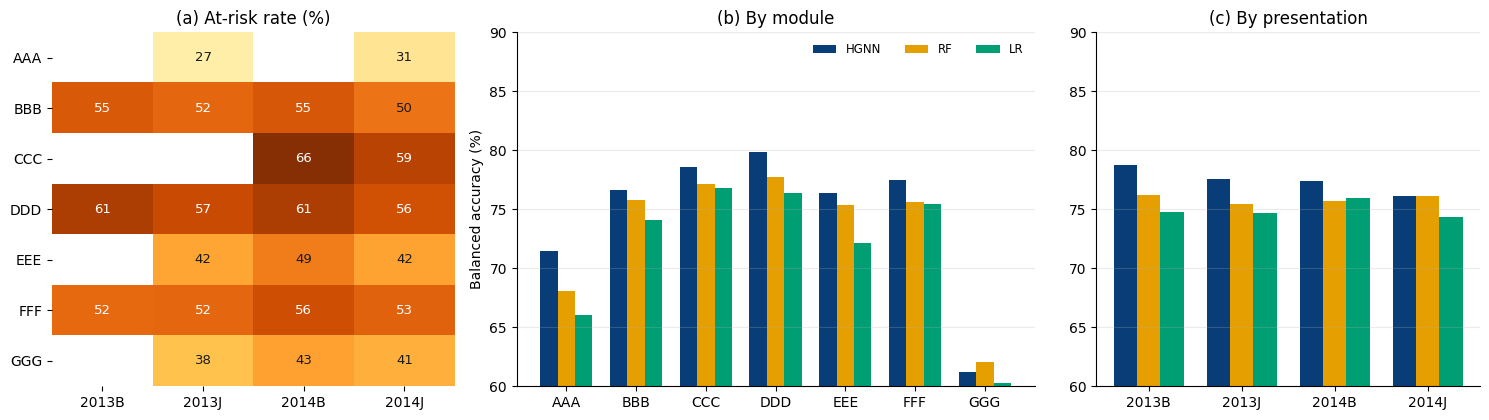

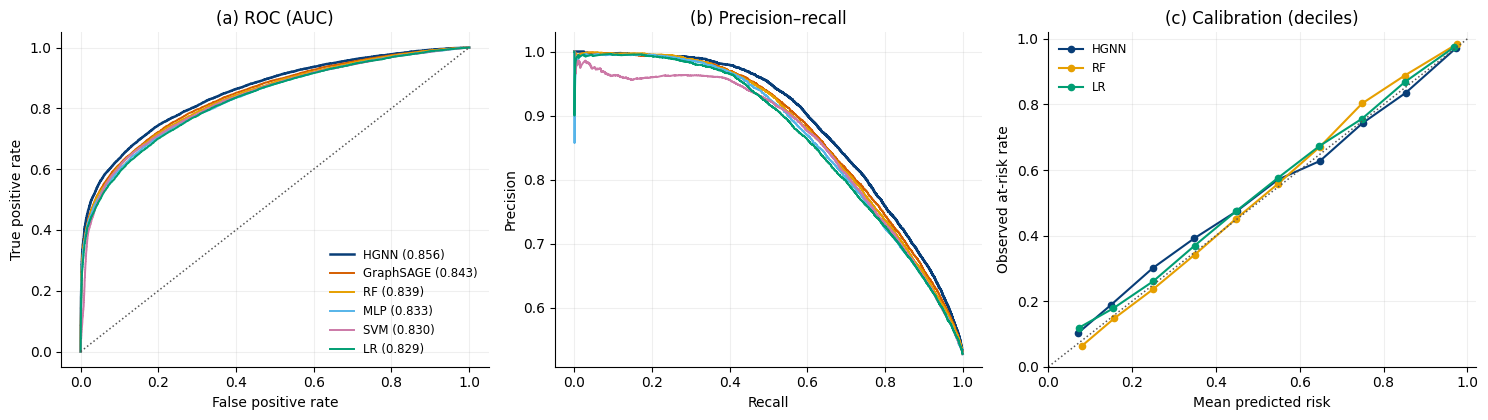

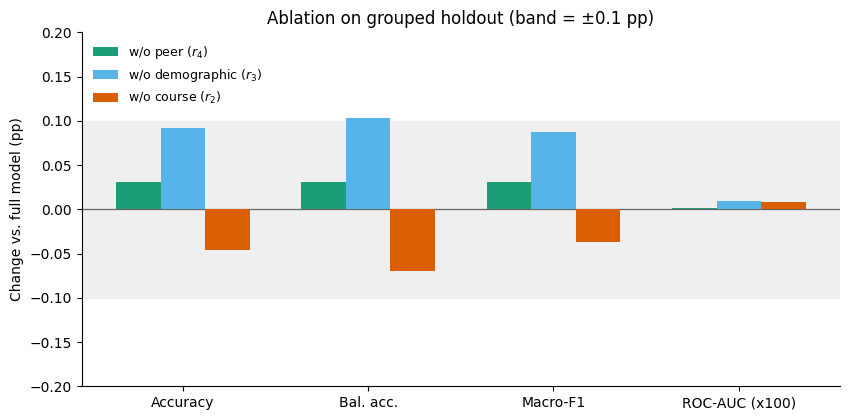

In [9]:
# === Paper Tables III & V + Figures 3, 4, 5, and 7 (Classification & Ablation) ===
import re
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    balanced_accuracy_score,
)

# Load from in-memory variables if available; otherwise fall back to saved OUTPUT_DIR CSVs.
_cv_metrics = globals().get("cv_metrics")
if _cv_metrics is None:
    _cv_metrics = pd.read_csv(OUTPUT_DIR / "nested_grouped_cv_outer_fold_metrics.csv")

_oof = globals().get("oof")
if _oof is None:
    _oof = pd.read_csv(OUTPUT_DIR / "nested_grouped_cv_oof_predictions.csv")

_paired_holdout = globals().get("paired_classification_summary")
if _paired_holdout is None:
    _paired_holdout = pd.read_csv(OUTPUT_DIR / "grouped_holdout_paired_user_bootstrap_vs_hgnn.csv")

_holdout_metrics = globals().get("holdout_metrics")
if _holdout_metrics is None and (OUTPUT_DIR / "grouped_holdout_80_20_metrics.csv").exists():
    _holdout_metrics = pd.read_csv(OUTPUT_DIR / "grouped_holdout_80_20_metrics.csv")

_ablation_metrics = globals().get("ablation_metrics")
if _ablation_metrics is None and (OUTPUT_DIR / "oulad_holdout_ablation_metrics.csv").exists():
    _ablation_metrics = pd.read_csv(OUTPUT_DIR / "oulad_holdout_ablation_metrics.csv")

_model_list = list(globals().get(
    "model_names",
    ["HGNN", "Logistic Regression", "Random Forest", "SVM (RBF)", "MLP", "GraphSAGE"],
))
_short_names = {
    "HGNN": "HGNN",
    "Random Forest": "RF",
    "GraphSAGE": "GraphSAGE",
    "SVM (RBF)": "SVM",
    "MLP": "MLP",
    "Logistic Regression": "LR",
}
_model_colors = {
    "HGNN": "#083D77",
    "Random Forest": "#E69F00",
    "GraphSAGE": "#D55E00",
    "SVM (RBF)": "#CC79A7",
    "MLP": "#56B4E9",
    "Logistic Regression": "#009E73",
}

# Detect CV seeds from OOF columns (matches CV_SEEDS, e.g., [42, 52]).
_seed_matches = sorted({
    int(m.group(1))
    for col in _oof.columns
    for m in [re.match(r"^OOF_HGNN_seed_(\d+)$", str(col))]
    if m
})
_cv_seeds = _seed_matches if _seed_matches else list(globals().get("CV_SEEDS", [42, 52]))
_y_oof = _oof["At_Risk"].to_numpy(dtype=np.int64)


def _compute_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_prob = np.asarray(y_prob, dtype=np.float64)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n_total = len(y_true)
    for b in range(n_bins):
        lo, hi = bins[b], bins[b + 1]
        mask = (y_prob >= lo) & (y_prob <= hi if b == n_bins - 1 else y_prob < hi)
        if np.any(mask):
            ece += (np.sum(mask) / n_total) * abs(float(y_true[mask].mean()) - float(y_prob[mask].mean()))
    return float(ece)


def _weighted_bal_acc_2seed(y_true, prob_matrix, weights=None):
    """Exact balanced accuracy averaged across seeds for a subset/weight vector."""
    scores = []
    pos_mask = (y_true == 1)
    neg_mask = ~pos_mask
    for s_idx in range(prob_matrix.shape[1]):
        pred = (prob_matrix[:, s_idx] >= 0.5)
        if weights is None:
            tpr = float(pred[pos_mask].mean()) if np.any(pos_mask) else 0.0
            tnr = float((~pred[neg_mask]).mean()) if np.any(neg_mask) else 0.0
        else:
            p_w = float(weights[pos_mask].sum())
            n_w = float(weights[neg_mask].sum())
            tpr = float(weights[pos_mask & pred].sum() / p_w) if p_w > 0 else 0.0
            tnr = float(weights[neg_mask & (~pred)].sum() / n_w) if n_w > 0 else 0.0
        scores.append(0.5 * (tpr + tnr))
    return float(np.mean(scores))


# --- Table III: Pooled OOF probability quality (mean over CV seeds) ---
_prob_quality_rows = []
_mean_auc_by_model = {}
for m in _model_list:
    aucs, aps, briers, eces = [], [], [], []
    for s in _cv_seeds:
        col = f"OOF_{m}_seed_{s}"
        if col not in _oof.columns:
            continue
        p = _oof[col].to_numpy(dtype=np.float64)
        valid = np.isfinite(p)
        yv, pv = _y_oof[valid], p[valid]
        aucs.append(roc_auc_score(yv, pv))
        aps.append(average_precision_score(yv, pv))
        briers.append(float(np.mean((yv - pv) ** 2)))
        eces.append(_compute_ece(yv, pv, n_bins=10))
    if aucs:
        _mean_auc_by_model[m] = float(np.mean(aucs))
        _prob_quality_rows.append({
            "Model": m,
            "ROC-AUC": float(np.mean(aucs)),
            "AP": float(np.mean(aps)),
            "Brier": float(np.mean(briers)),
            "ECE": float(np.mean(eces)),
        })

table_III_prob_quality = pd.DataFrame(_prob_quality_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
print("=== TABLE III: PROBABILITY QUALITY (POOLED OOF, MEAN OVER SEEDS) ===")
display(table_III_prob_quality.round(4))
table_III_prob_quality.to_csv(OUTPUT_DIR / "publication_table_III_probability_quality.csv", index=False)

# --- Table V: Paired learner-level bootstrap (1,000 replicates) on CV OOF predictions ---
_oof_groups = _oof["id_student"].astype(str).to_numpy()
_unique_learners = np.unique(_oof_groups)
_learner_codes = pd.Categorical(_oof_groups, categories=_unique_learners).codes
_n_learners = len(_unique_learners)

# Pre-aggregate per-learner counts for exact vectorized 1,000-replicate bootstrap.
_learner_pos = np.bincount(_learner_codes, weights=(_y_oof == 1).astype(np.float64), minlength=_n_learners)
_learner_neg = np.bincount(_learner_codes, weights=(_y_oof == 0).astype(np.float64), minlength=_n_learners)
_learner_tp = {}
_learner_tn = {}
for m in _model_list:
    tp_seeds, tn_seeds = [], []
    for s in _cv_seeds:
        col = f"OOF_{m}_seed_{s}"
        if col not in _oof.columns:
            continue
        pred = (_oof[col].to_numpy(dtype=np.float64) >= 0.5)
        tp_seeds.append(np.bincount(_learner_codes, weights=((_y_oof == 1) & pred).astype(np.float64), minlength=_n_learners))
        tn_seeds.append(np.bincount(_learner_codes, weights=((_y_oof == 0) & (~pred)).astype(np.float64), minlength=_n_learners))
    _learner_tp[m] = np.stack(tp_seeds, axis=0)  # [S, G]
    _learner_tn[m] = np.stack(tn_seeds, axis=0)  # [S, G]

_boot_rng = np.random.RandomState(SEED + 505)
_cv_boot_deltas = {m: [] for m in _model_list if m != "HGNN"}
for _ in range(1000):
    sampled = _boot_rng.randint(0, _n_learners, size=_n_learners)
    mult = np.bincount(sampled, minlength=_n_learners).astype(np.float64)
    p_tot = float(mult @ _learner_pos)
    n_tot = float(mult @ _learner_neg)
    if p_tot <= 0 or n_tot <= 0:
        continue
    _bal_by_model = {}
    for m in _model_list:
        tprs = (_learner_tp[m] @ mult) / p_tot
        tnrs = (_learner_tn[m] @ mult) / n_tot
        _bal_by_model[m] = float(np.mean(0.5 * (tprs + tnrs)))
    for m in _cv_boot_deltas:
        _cv_boot_deltas[m].append(_bal_by_model[m] - _bal_by_model["HGNN"])

_table_V_rows = []
for m in _cv_boot_deltas:
    arr = np.asarray(_cv_boot_deltas[m], dtype=np.float64)
    _table_V_rows.append({
        "Baseline Comparison": f"{m} vs. HGNN",
        "Delta_mean": float(arr.mean()),
        "CI95_low": float(np.quantile(arr, 0.025)),
        "CI95_high": float(np.quantile(arr, 0.975)),
    })
table_V_cv_bootstrap = pd.DataFrame(_table_V_rows)
print("=== TABLE V: PAIRED LEARNER-LEVEL BOOTSTRAP ON CV OOF (1,000 REPLICATES) ===")
display(table_V_cv_bootstrap.round(4))
table_V_cv_bootstrap.to_csv(OUTPUT_DIR / "publication_table_V_cv_oof_paired_bootstrap.csv", index=False)


# ================= FIGURE 3: Outer-fold Balanced Accuracy + Paired Bootstrap CIs =================
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.05, 1.0]})

_order_fig3a = (
    _cv_metrics.groupby("Model")["Balanced_accuracy"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
_box_vals = [(_cv_metrics.loc[_cv_metrics["Model"] == m, "Balanced_accuracy"].to_numpy() * 100.0) for m in _order_fig3a]
_bp = ax3a.boxplot(
    _box_vals,
    positions=np.arange(len(_order_fig3a)),
    widths=0.52,
    showfliers=False,
    patch_artist=True,
    medianprops={"color": "#1A1A1A", "linewidth": 1.8},
    whiskerprops={"color": "#4A4A4A", "linewidth": 1.0},
    capprops={"color": "#4A4A4A", "linewidth": 1.0},
)
for patch, m in zip(_bp["boxes"], _order_fig3a):
    patch.set_facecolor(_model_colors[m])
    patch.set_alpha(0.32)
    patch.set_edgecolor(_model_colors[m])
    patch.set_linewidth(1.1)

_jitter_rng = np.random.RandomState(SEED + 31)
for idx_m, m in enumerate(_order_fig3a):
    sub = _cv_metrics.loc[_cv_metrics["Model"] == m].sort_values(["Seed", "Fold"])
    for s_idx, s in enumerate(sorted(sub["Seed"].unique())):
        vals = sub.loc[sub["Seed"] == s, "Balanced_accuracy"].to_numpy() * 100.0
        xs = idx_m + _jitter_rng.uniform(-0.16, 0.16, size=len(vals))
        ax3a.scatter(
            xs, vals, s=26, zorder=4,
            facecolor=_model_colors[m] if s_idx == 0 else "white",
            edgecolor=_model_colors[m], linewidth=1.2,
            label=f"Seed {s}" if idx_m == 0 else None,
        )

ax3a.set_xticks(np.arange(len(_order_fig3a)))
ax3a.set_xticklabels([_short_names.get(m, m) for m in _order_fig3a])
ax3a.set_ylabel("Balanced accuracy (%)")
ax3a.set_title("(a) Ten outer test folds (2 seeds × 5 folds)")
ax3a.grid(axis="y", alpha=0.25)
ax3a.spines["top"].set_visible(False)
ax3a.spines["right"].set_visible(False)

# Panel (b): Paired bootstrap forest plot (CV OOF 1,000 rep vs Grouped holdout 200 rep)
_baselines_order_b = ["Logistic Regression", "MLP", "SVM (RBF)", "Random Forest", "GraphSAGE"]
_baselines_order_b = [m for m in _baselines_order_b if m in _model_list]
_cv_map = table_V_cv_bootstrap.set_index("Baseline Comparison")
_hold_map = _paired_holdout.set_index("Comparison")

_y_pos = np.arange(len(_baselines_order_b), dtype=float)
_cv_means, _cv_lo, _cv_hi = [], [], []
_ho_means, _ho_lo, _ho_hi = [], [], []
for m in _baselines_order_b:
    row_cv = _cv_map.loc[f"{m} vs. HGNN"]
    _cv_means.append(row_cv["Delta_mean"] * 100.0)
    _cv_lo.append(row_cv["CI95_low"] * 100.0)
    _cv_hi.append(row_cv["CI95_high"] * 100.0)

    row_ho = _hold_map.loc[f"{m} - HGNN"]
    _ho_means.append(row_ho["Delta_mean"] * 100.0)
    _ho_lo.append(row_ho["CI95_low"] * 100.0)
    _ho_hi.append(row_ho["CI95_high"] * 100.0)

_cv_means, _cv_lo, _cv_hi = np.asarray(_cv_means), np.asarray(_cv_lo), np.asarray(_cv_hi)
_ho_means, _ho_lo, _ho_hi = np.asarray(_ho_means), np.asarray(_ho_lo), np.asarray(_ho_hi)

ax3b.axvline(0.0, color="#333333", linestyle="--", linewidth=1.1, zorder=1)
ax3b.errorbar(
    _cv_means, _y_pos + 0.13,
    xerr=[np.maximum(0.0, _cv_means - _cv_lo), np.maximum(0.0, _cv_hi - _cv_means)],
    fmt="o", color="#083D77", ecolor="#083D77", elinewidth=1.6, capsize=3.5, markersize=6,
    label="CV out-of-fold (1,000 rep.)", zorder=3,
)
ax3b.errorbar(
    _ho_means, _y_pos - 0.13,
    xerr=[np.maximum(0.0, _ho_means - _ho_lo), np.maximum(0.0, _ho_hi - _ho_means)],
    fmt="s", color="#C55A11", ecolor="#C55A11", elinewidth=1.6, capsize=3.5, markersize=5.5,
    label="Grouped holdout (200 rep.)", zorder=3,
)
ax3b.set_yticks(_y_pos)
ax3b.set_yticklabels([_short_names.get(m, m) for m in _baselines_order_b])
ax3b.set_xlabel("Baseline − HGNN, balanced accuracy (pp)")
ax3b.set_title("(b) Paired bootstrap, 95% CI")
ax3b.set_xlim(min(-4.3, float(np.min(_ho_lo)) - 0.35, float(np.min(_cv_lo)) - 0.35), 0.35)
ax3b.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white", framealpha=0.92)
ax3b.grid(axis="x", alpha=0.25)
ax3b.spines["top"].set_visible(False)
ax3b.spines["right"].set_visible(False)

fig3.tight_layout()
fig3.savefig(OUTPUT_DIR / "fig3_cv_folds_and_paired_bootstrap.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig3)


# ================= FIGURE 4: At-risk Heatmap & Module/Presentation Breakdown =================
def _pres_sort_key(val):
    s = str(val)
    return (int(s[:4]) if s[:4].isdigit() else 9999, {"B": 0, "J": 1}.get(s[4:], 2), s)

_diag_frame = _oof[["code_module", "code_presentation", "At_Risk"]].copy()
_modules_sorted = sorted(_diag_frame["code_module"].astype(str).unique())
_pres_sorted = sorted(_diag_frame["code_presentation"].astype(str).unique(), key=_pres_sort_key)

_heat = (
    _diag_frame.groupby(["code_module", "code_presentation"])["At_Risk"]
    .mean()
    .unstack("code_presentation")
    .reindex(index=_modules_sorted, columns=_pres_sorted) * 100.0
)

fig4, (ax4a, ax4b, ax4c) = plt.subplots(1, 3, figsize=(15.0, 4.3), gridspec_kw={"width_ratios": [1.05, 1.35, 1.0]})

_cmap = plt.cm.YlOrBr.copy()
_cmap.set_bad(color="white")
_heat_vals = np.ma.masked_invalid(_heat.to_numpy(dtype=np.float64))
ax4a.imshow(_heat_vals, cmap=_cmap, vmin=18, vmax=70, aspect="auto")
ax4a.set_xticks(np.arange(len(_pres_sorted)))
ax4a.set_xticklabels(_pres_sorted)
ax4a.set_yticks(np.arange(len(_modules_sorted)))
ax4a.set_yticklabels(_modules_sorted)
ax4a.set_title("(a) At-risk rate (%)")
for r_i in range(len(_modules_sorted)):
    for c_i in range(len(_pres_sorted)):
        val = _heat.iloc[r_i, c_i]
        if np.isfinite(val):
            ax4a.text(
                c_i, r_i, f"{int(round(val))}",
                ha="center", va="center", fontsize=9.5, fontweight="medium",
                color="white" if val >= 50.0 else "#1A1A1A",
            )
for spine in ax4a.spines.values():
    spine.set_visible(False)

_sub_models = [m for m in ["HGNN", "Random Forest", "Logistic Regression"] if m in _model_list]
_sub_colors = {"HGNN": "#083D77", "Random Forest": "#E69F00", "Logistic Regression": "#009E73"}
_sub_labels = {"HGNN": "HGNN", "Random Forest": "RF", "Logistic Regression": "LR"}

def _subgroup_bal_acc(group_col, group_order):
    out = {m: [] for m in _sub_models}
    for g_val in group_order:
        mask = _oof[group_col].astype(str).eq(str(g_val)).to_numpy()
        y_sub = _y_oof[mask]
        for m in _sub_models:
            cols = [f"OOF_{m}_seed_{s}" for s in _cv_seeds if f"OOF_{m}_seed_{s}" in _oof.columns]
            p_mat = _oof.loc[mask, cols].to_numpy(dtype=np.float64)
            out[m].append(_weighted_bal_acc_2seed(y_sub, p_mat) * 100.0)
    return out

_mod_scores = _subgroup_bal_acc("code_module", _modules_sorted)
_pres_scores = _subgroup_bal_acc("code_presentation", _pres_sorted)

_bw = 0.25
_x_mod = np.arange(len(_modules_sorted))
for idx_m, m in enumerate(_sub_models):
    ax4b.bar(
        _x_mod + (idx_m - 1) * _bw, _mod_scores[m], width=_bw,
        color=_sub_colors[m], label=_sub_labels[m],
    )
ax4b.set_xticks(_x_mod)
ax4b.set_xticklabels(_modules_sorted)
ax4b.set_ylim(60, 90)
ax4b.set_ylabel("Balanced accuracy (%)")
ax4b.set_title("(b) By module")
ax4b.legend(loc="upper right", ncol=3, fontsize=8.5, frameon=False)
ax4b.grid(axis="y", alpha=0.25)
ax4b.spines["top"].set_visible(False)
ax4b.spines["right"].set_visible(False)

_x_pres = np.arange(len(_pres_sorted))
for idx_m, m in enumerate(_sub_models):
    ax4c.bar(
        _x_pres + (idx_m - 1) * _bw, _pres_scores[m], width=_bw,
        color=_sub_colors[m], label=_sub_labels[m],
    )
ax4c.set_xticks(_x_pres)
ax4c.set_xticklabels(_pres_sorted)
ax4c.set_ylim(60, 90)
ax4c.set_title("(c) By presentation")
ax4c.grid(axis="y", alpha=0.25)
ax4c.spines["top"].set_visible(False)
ax4c.spines["right"].set_visible(False)

fig4.tight_layout()
fig4.savefig(OUTPUT_DIR / "fig4_module_and_presentation_analysis.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig4)


# ================= FIGURE 5: Pooled OOF ROC, Precision-Recall, and Calibration =================
_curve_seed = _cv_seeds[0]
_roc_order = table_III_prob_quality["Model"].tolist()

fig5, (ax5a, ax5b, ax5c) = plt.subplots(1, 3, figsize=(15.0, 4.3))

for m in _roc_order:
    p = _oof[f"OOF_{m}_seed_{_curve_seed}"].to_numpy(dtype=np.float64)
    fpr, tpr, _ = roc_curve(_y_oof, p)
    ax5a.plot(
        fpr, tpr, linewidth=1.8 if m == "HGNN" else 1.4,
        color=_model_colors[m],
        label=f"{_short_names[m]} ({_mean_auc_by_model[m]:.3f})",
    )
    prec, rec, _ = precision_recall_curve(_y_oof, p)
    ax5b.plot(
        rec, prec, linewidth=1.8 if m == "HGNN" else 1.4,
        color=_model_colors[m], label=_short_names[m],
    )

ax5a.plot([0, 1], [0, 1], ":", color="#555555", linewidth=1.1)
ax5a.set_xlabel("False positive rate")
ax5a.set_ylabel("True positive rate")
ax5a.set_title("(a) ROC (AUC)")
ax5a.legend(loc="lower right", fontsize=8.5, frameon=False)
ax5a.grid(alpha=0.2)
ax5a.spines["top"].set_visible(False)
ax5a.spines["right"].set_visible(False)

ax5b.set_xlabel("Recall")
ax5b.set_ylabel("Precision")
ax5b.set_title("(b) Precision\u2013recall")
ax5b.set_ylim(max(0.50, float(_y_oof.mean()) - 0.02), 1.03)
ax5b.grid(alpha=0.2)
ax5b.spines["top"].set_visible(False)
ax5b.spines["right"].set_visible(False)

_cal_bins = np.linspace(0.0, 1.0, 11)
for m in _sub_models:
    p = _oof[f"OOF_{m}_seed_{_curve_seed}"].to_numpy(dtype=np.float64)
    bin_pred, bin_obs = [], []
    for b in range(10):
        lo, hi = _cal_bins[b], _cal_bins[b + 1]
        mask = (p >= lo) & (p <= hi if b == 9 else p < hi)
        if np.any(mask):
            bin_pred.append(float(p[mask].mean()))
            bin_obs.append(float(_y_oof[mask].mean()))
    ax5c.plot(
        bin_pred, bin_obs, marker="o", markersize=4.5, linewidth=1.5,
        color=_sub_colors[m], label=_sub_labels[m],
    )
ax5c.plot([0, 1], [0, 1], ":", color="#555555", linewidth=1.1)
ax5c.set_xlabel("Mean predicted risk")
ax5c.set_ylabel("Observed at-risk rate")
ax5c.set_title("(c) Calibration (deciles)")
ax5c.set_xlim(0.0, 1.02)
ax5c.set_ylim(0.0, 1.02)
ax5c.legend(loc="upper left", fontsize=8.5, frameon=False)
ax5c.grid(alpha=0.2)
ax5c.spines["top"].set_visible(False)
ax5c.spines["right"].set_visible(False)

fig5.tight_layout()
fig5.savefig(OUTPUT_DIR / "fig5_pooled_oof_roc_pr_calibration.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig5)


# ================= FIGURE 7: Holdout Relation Ablation Delta (pp) =================
if _ablation_metrics is not None and not _ablation_metrics.empty and _holdout_metrics is not None:
    _full_row = _holdout_metrics.loc[_holdout_metrics["Model"] == "HGNN"].iloc[0]
    _abl_specs = [
        ("Remove peer similarity", "w/o peer ($r_4$)", "#1B9E77"),
        ("Remove demographic attributes", "w/o demographic ($r_3$)", "#56B4E9"),
        ("Remove course relations", "w/o course ($r_2$)", "#D95F02"),
    ]
    _abl_metrics_cols = ["Accuracy", "Balanced_accuracy", "F1_macro", "ROC_AUC"]
    _abl_x_labels = ["Accuracy", "Bal. acc.", "Macro-F1", "ROC-AUC (x100)"]

    fig7, ax7 = plt.subplots(figsize=(8.6, 4.3))
    ax7.axhspan(-0.1, 0.1, color="#EFEFEF", zorder=0)
    ax7.axhline(0.0, color="#666666", linewidth=0.9, zorder=1)

    _x_abl = np.arange(len(_abl_metrics_cols), dtype=float)
    _bw_abl = 0.24
    _abl_by_name = _ablation_metrics.set_index("Ablation")
    _max_abs = 0.18
    for idx_a, (raw_name, disp_name, color) in enumerate(_abl_specs):
        if raw_name not in _abl_by_name.index:
            continue
        deltas_pp = [
            float(_abl_by_name.loc[raw_name, col] - _full_row[col]) * 100.0
            for col in _abl_metrics_cols
        ]
        _max_abs = max(_max_abs, max(abs(v) for v in deltas_pp) + 0.04)
        ax7.bar(_x_abl + (idx_a - 1) * _bw_abl, deltas_pp, width=_bw_abl, color=color, label=disp_name, zorder=3)

    ax7.set_xticks(_x_abl)
    ax7.set_xticklabels(_abl_x_labels)
    ax7.set_ylabel("Change vs. full model (pp)")
    ax7.set_ylim(-max(0.20, _max_abs), max(0.20, _max_abs))
    ax7.set_title("Ablation on grouped holdout (band = \u00b10.1 pp)")
    ax7.legend(loc="upper left", fontsize=9, frameon=False)
    ax7.spines["top"].set_visible(False)
    ax7.spines["right"].set_visible(False)
    fig7.tight_layout()
    fig7.savefig(OUTPUT_DIR / "fig7_holdout_ablation_delta_pp.png", dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig7)
else:
    print("Skipped Figure 7: holdout or ablation metrics not available.")


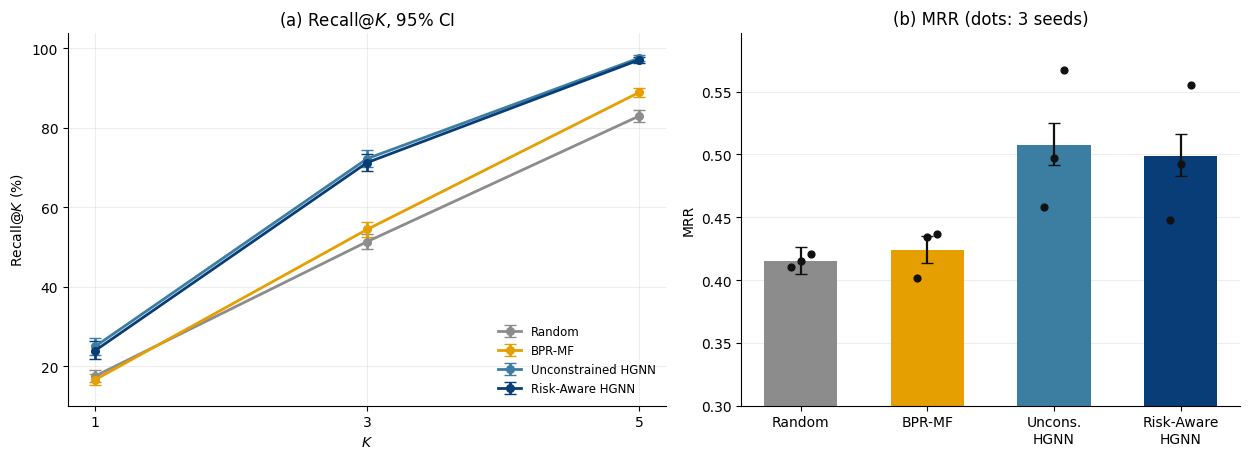

Top-1 module changed between Unconstrained and Risk-Aware HGNN on 1.97% of (learner, seed) pairs.
=== TABLE VIII: MEAN FAILURE RATE (%) OF TOP-1 RECOMMENDED MODULE ON 2014J ===


,All (861),$\rho_u \geq 0.5$ (138),$\rho_u < 0.5$ (723)
Random,48.3,47.6,48.4
BPR-MF,48.8,48.0,48.9
Unconstrained HGNN,52.4,52.6,52.4
Risk-Aware HGNN,51.8,49.2,52.4
Delta pp (Risk-Aware - Unconstr.),"-0.55 [-0.73, -0.38]","-3.43 [-4.33, -2.52]",0.00


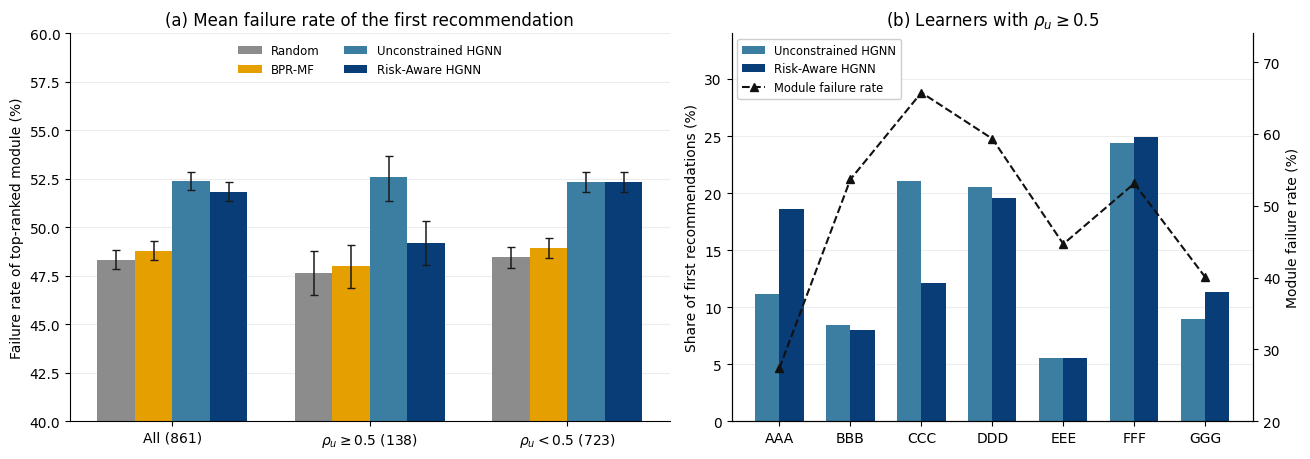

In [10]:
# === Paper Figures 8 & 9 + Table VIII (Temporal Recommendation & Safety Analysis) ===
_rank_by_seed = globals().get("temporal_ranking_by_seed_model")
if _rank_by_seed is None:
    _rank_by_seed = pd.read_csv(OUTPUT_DIR / "oulad_temporal_ranking_metrics_by_seed_model.csv")

_rank_ci = globals().get("ranking_user_bootstrap_ci")
if _rank_ci is None:
    _rank_ci = pd.read_csv(OUTPUT_DIR / "oulad_temporal_ranking_user_bootstrap_ci.csv")

_top5_all = globals().get("temporal_top5")
if _top5_all is None:
    _top5_all = pd.read_csv(OUTPUT_DIR / "oulad_temporal_ranking_top5_by_user_model.csv")

_rank_history_df = globals().get("rank_history")
if _rank_history_df is None:
    if "base" in globals() and isinstance(globals()["base"], pd.DataFrame):
        _b = globals()["base"]
        _target_p = str(_top5_all["Target_Presentation"].iloc[0]) if not _top5_all.empty else "2014J"
        _rank_history_df = _b.loc[_b["code_presentation"].astype(str).ne(_target_p)].copy()
    else:
        raise RuntimeError("rank_history (or base) is required for module/learner training failure rates.")

_rec_models = ["Random", "BPR-MF", "HGNN", "HGNN (Risk-Aware)"]
_rec_labels = {
    "Random": "Random",
    "BPR-MF": "BPR-MF",
    "HGNN": "Unconstrained HGNN",
    "HGNN (Risk-Aware)": "Risk-Aware HGNN",
}
_rec_short_2line = {
    "Random": "Random",
    "BPR-MF": "BPR-MF",
    "HGNN": "Uncons.\nHGNN",
    "HGNN (Risk-Aware)": "Risk-Aware\nHGNN",
}
_rec_colors = {
    "Random": "#8C8C8C",
    "BPR-MF": "#E69F00",
    "HGNN": "#3B7EA1",
    "HGNN (Risk-Aware)": "#083D77",
}

_ci_idx = _rank_ci.set_index(["Model", "Metric"])


# ================= FIGURE 8: Recall@K & MRR on 2014J =================
fig8, (ax8a, ax8b) = plt.subplots(1, 2, figsize=(12.6, 4.7), gridspec_kw={"width_ratios": [1.2, 1.0]})

_ks = list(globals().get("RANKING_KS", [1, 3, 5]))
for m in _rec_models:
    means, err_lo, err_hi = [], [], []
    for k in _ks:
        r = _ci_idx.loc[(m, f"Recall@{k}")]
        mean_pct = float(r["Mean"]) * 100.0
        means.append(mean_pct)
        err_lo.append(max(0.0, mean_pct - float(r["CI95_low"]) * 100.0))
        err_hi.append(max(0.0, float(r["CI95_high"]) * 100.0 - mean_pct))
    ax8a.errorbar(
        _ks, means, yerr=[err_lo, err_hi], marker="o", linewidth=2.0, capsize=4,
        markersize=5.5, color=_rec_colors[m], label=_rec_labels[m],
    )

ax8a.set_xticks(_ks)
ax8a.set_xlabel("$K$")
ax8a.set_ylabel("Recall@$K$ (%)")
ax8a.set_ylim(10, 104)
ax8a.set_title("(a) Recall@$K$, 95% CI")
ax8a.legend(loc="lower right", fontsize=8.5, frameon=False)
ax8a.grid(alpha=0.22)
ax8a.spines["top"].set_visible(False)
ax8a.spines["right"].set_visible(False)

_x_mrr = np.arange(len(_rec_models), dtype=float)
_mrr_means, _mrr_lo, _mrr_hi = [], [], []
for m in _rec_models:
    r = _ci_idx.loc[(m, "MRR")]
    val = float(r["Mean"])
    _mrr_means.append(val)
    _mrr_lo.append(max(0.0, val - float(r["CI95_low"])))
    _mrr_hi.append(max(0.0, float(r["CI95_high"]) - val))

ax8b.bar(
    _x_mrr, _mrr_means, width=0.58,
    color=[_rec_colors[m] for m in _rec_models],
    yerr=[_mrr_lo, _mrr_hi], error_kw={"ecolor": "#111111", "elinewidth": 1.6, "capsize": 4},
    zorder=2,
)
for idx_m, m in enumerate(_rec_models):
    seed_vals = np.sort(_rank_by_seed.loc[_rank_by_seed["Model"] == m, "MRR"].to_numpy(dtype=np.float64))
    offsets = np.linspace(-0.08, 0.08, len(seed_vals)) if len(seed_vals) > 1 else np.asarray([0.0])
    ax8b.scatter(
        np.full(len(seed_vals), idx_m) + offsets, seed_vals,
        color="#111111", s=24, zorder=4,
    )

ax8b.set_xticks(_x_mrr)
ax8b.set_xticklabels([_rec_short_2line[m] for m in _rec_models])
ax8b.set_ylabel("MRR")
ax8b.set_ylim(0.30, max(0.58, float(_rank_by_seed["MRR"].max()) + 0.03))
ax8b.set_title("(b) MRR (dots: 3 seeds)")
ax8b.grid(axis="y", alpha=0.22)
ax8b.spines["top"].set_visible(False)
ax8b.spines["right"].set_visible(False)

fig8.tight_layout()
fig8.savefig(OUTPUT_DIR / "fig8_recommendation_recall_and_mrr.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig8)


# ================= TABLE VIII & FIGURE 9: Safety Analysis on 2014J =================
_user_col_top5 = "Student_ID" if "Student_ID" in _top5_all.columns else "User_ID"
_module_fail_rate = (
    _rank_history_df.groupby(_rank_history_df["code_module"].astype(str))["At_Risk"].mean() * 100.0
).to_dict()
_learner_hist_risk = (
    _rank_history_df.groupby(_rank_history_df["id_student"].astype(str))["At_Risk"].mean()
).to_dict()

_top1 = _top5_all.loc[_top5_all["Rank"] == 1].copy()
_top1["Student_ID"] = _top1[_user_col_top5].astype(str)
_top1["Recommended_Module"] = _top1["Recommended_Module"].astype(str)
_top1["rho_u"] = _top1["Student_ID"].map(_learner_hist_risk).fillna(0.5)
_top1["High_Risk_Group"] = _top1["rho_u"] >= 0.50
_top1["Fail_Rate_Pct"] = _top1["Recommended_Module"].map(_module_fail_rate)

# Average Top-1 failure rate across seeds for each (Model, Student_ID) as in Table VIII / Fig. 9(a).
_user_top1_mean = (
    _top1.groupby(["Model", "Student_ID", "High_Risk_Group"], as_index=False)["Fail_Rate_Pct"].mean()
)

_n_all = _user_top1_mean.loc[_user_top1_mean["Model"] == "HGNN", "Student_ID"].nunique()
_n_high = _user_top1_mean.loc[
    (_user_top1_mean["Model"] == "HGNN") & (_user_top1_mean["High_Risk_Group"]), "Student_ID"
].nunique()
_n_low = _n_all - _n_high

_safety_groups = [
    ("All", f"All ({_n_all})", None),
    ("high", rf"$\rho_u \geq 0.5$ ({_n_high})", True),
    ("low", rf"$\rho_u < 0.5$ ({_n_low})", False),
]


def _bootstrap_mean_ci(values, rng, n_boot=2000):
    arr = np.asarray(values, dtype=np.float64)
    if len(arr) == 0:
        return np.nan, np.nan, np.nan
    boot = rng.choice(arr, size=(n_boot, len(arr)), replace=True).mean(axis=1)
    return float(arr.mean()), float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975))


_safety_rng = np.random.RandomState(SEED + 950)
_safety_stats = {}  # (model, group_key) -> (mean, ci_low, ci_high)
_table_VIII_dict = {m: {} for m in _rec_models}
_delta_row = {}

for g_key, g_label, g_flag in _safety_groups:
    sub_g = _user_top1_mean if g_flag is None else _user_top1_mean.loc[_user_top1_mean["High_Risk_Group"] == g_flag]
    for m in _rec_models:
        vals = sub_g.loc[sub_g["Model"] == m, "Fail_Rate_Pct"].to_numpy(dtype=np.float64)
        mean_v, lo_v, hi_v = _bootstrap_mean_ci(vals, _safety_rng, n_boot=2000)
        _safety_stats[(m, g_key)] = (mean_v, lo_v, hi_v)
        _table_VIII_dict[m][g_label] = round(mean_v, 1)

    wide_g = sub_g.pivot(index="Student_ID", columns="Model", values="Fail_Rate_Pct").dropna(
        subset=["HGNN", "HGNN (Risk-Aware)"]
    )
    delta_vals = (wide_g["HGNN (Risk-Aware)"] - wide_g["HGNN"]).to_numpy(dtype=np.float64)
    d_mean, d_lo, d_hi = _bootstrap_mean_ci(delta_vals, _safety_rng, n_boot=2000)
    _delta_row[g_label] = f"{d_mean:.2f} [{d_lo:.2f}, {d_hi:.2f}]" if abs(d_mean) > 1e-9 else "0.00"

# Report share of (learner, seed) pairs whose Rank-1 module changed under the risk penalty.
_top1_pair_wide = _top1.pivot(index=["Seed", "Student_ID"], columns="Model", values="Recommended_Module").dropna(
    subset=["HGNN", "HGNN (Risk-Aware)"]
)
_changed_pct = float((_top1_pair_wide["HGNN"] != _top1_pair_wide["HGNN (Risk-Aware)"]).mean() * 100.0)
print(f"Top-1 module changed between Unconstrained and Risk-Aware HGNN on {_changed_pct:.2f}% of (learner, seed) pairs.")

table_VIII_safety = pd.DataFrame.from_dict(_table_VIII_dict, orient="index")
table_VIII_safety.index = [_rec_labels[m] for m in table_VIII_safety.index]
table_VIII_safety.loc["Delta pp (Risk-Aware - Unconstr.)"] = _delta_row
print("=== TABLE VIII: MEAN FAILURE RATE (%) OF TOP-1 RECOMMENDED MODULE ON 2014J ===")
display(table_VIII_safety)
table_VIII_safety.to_csv(OUTPUT_DIR / "publication_table_VIII_safety_analysis.csv")


# ================= FIGURE 9: Safety Failure Rate + Module Shift =================
fig9, (ax9a, ax9b) = plt.subplots(1, 2, figsize=(13.2, 4.7), gridspec_kw={"width_ratios": [1.15, 1.0]})

_x_grp = np.arange(len(_safety_groups), dtype=float)
_bw_s = 0.19
for idx_m, m in enumerate(_rec_models):
    means = [_safety_stats[(m, g_key)][0] for g_key, _, _ in _safety_groups]
    lo_err = [max(0.0, _safety_stats[(m, g_key)][0] - _safety_stats[(m, g_key)][1]) for g_key, _, _ in _safety_groups]
    hi_err = [max(0.0, _safety_stats[(m, g_key)][2] - _safety_stats[(m, g_key)][0]) for g_key, _, _ in _safety_groups]
    ax9a.bar(
        _x_grp + (idx_m - 1.5) * _bw_s, means, width=_bw_s,
        color=_rec_colors[m], label=_rec_labels[m],
        yerr=[lo_err, hi_err], error_kw={"ecolor": "#1A1A1A", "elinewidth": 1.1, "capsize": 2.8},
        zorder=2,
    )

ax9a.set_xticks(_x_grp)
ax9a.set_xticklabels([g_label for _, g_label, _ in _safety_groups])
ax9a.set_ylabel("Failure rate of top-ranked module (%)")
ax9a.set_ylim(40.0, 60.0)
ax9a.set_title("(a) Mean failure rate of the first recommendation")
ax9a.legend(loc="upper center", ncol=2, fontsize=8.5, frameon=False)
ax9a.grid(axis="y", alpha=0.22)
ax9a.spines["top"].set_visible(False)
ax9a.spines["right"].set_visible(False)

# Panel (b): Share of Rank-1 recommendations per module for learners with rho_u >= 0.5
_mods_sorted_9 = sorted(_module_fail_rate)
_top1_high = _top1.loc[_top1["High_Risk_Group"]].copy()
_x_m9 = np.arange(len(_mods_sorted_9), dtype=float)
_bw_m9 = 0.34

for idx_m, m in enumerate(["HGNN", "HGNN (Risk-Aware)"]):
    sub_m = _top1_high.loc[_top1_high["Model"] == m]
    counts = sub_m["Recommended_Module"].value_counts()
    total = max(1, len(sub_m))
    shares = [float(counts.get(mod, 0)) / total * 100.0 for mod in _mods_sorted_9]
    ax9b.bar(
        _x_m9 + (idx_m - 0.5) * _bw_m9, shares, width=_bw_m9,
        color=_rec_colors[m], label=_rec_labels[m], zorder=2,
    )

ax9b.set_xticks(_x_m9)
ax9b.set_xticklabels(_mods_sorted_9)
ax9b.set_ylabel("Share of first recommendations (%)")
ax9b.set_ylim(0, 34)
ax9b.set_title(r"(b) Learners with $\rho_u \geq 0.5$")
ax9b.grid(axis="y", alpha=0.22)
ax9b.spines["top"].set_visible(False)

ax9b_r = ax9b.twinx()
_mod_fail_vals = [_module_fail_rate[mod] for mod in _mods_sorted_9]
ax9b_r.plot(
    _x_m9, _mod_fail_vals, linestyle="--", marker="^", color="#111111",
    linewidth=1.5, markersize=6, label="Module failure rate", zorder=4,
)
ax9b_r.set_ylabel("Module failure rate (%)")
ax9b_r.set_ylim(20, 74)
ax9b_r.spines["top"].set_visible(False)

_h1, _l1 = ax9b.get_legend_handles_labels()
_h2, _l2 = ax9b_r.get_legend_handles_labels()
ax9b.legend(
    _h1 + _h2, _l1 + _l2, loc="upper left", fontsize=8.3,
    frameon=True, facecolor="white", framealpha=0.95, edgecolor="#CCCCCC",
)

fig9.tight_layout()
fig9.savefig(OUTPUT_DIR / "fig9_safety_analysis_2014j.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig9)


## Interpretation and limitations

- The label derived from `final_result` is an at-risk proxy, not the base paper's exact engagement label.
- Grouped classification differs from the paper's stratified split and remains transductive in features/graph structure.
- OULAD has only a few modules available in the final presentation. Even a strong score in this catalog cannot establish scalable recommendation performance.
- The original OULAD notebook did not report temporal ranking metrics; the revised notebook adds a validation/test temporal protocol and a random ranking control.
- Classifier configurations are selected inside grouped validation within each outer training fold. Ranking epochs are chosen on the penultimate presentation, never on the final one.
- Wide user-level intervals indicate uncertainty and do not establish superiority. Attention entropy is not feature importance. This is an offline research experiment, not a deployed system.


## Outputs and conclusion scope

The notebook writes grouped classification metrics, a grouped holdout, same-split relation ablations, validation-selected ranking epochs, HGNN and random-control temporal ranking metrics, per-ranker user-bootstrap intervals, and top-5 module lists. The final module catalog is small; report its size and coverage beside every ranking result. Conclusions should distinguish the OULAD at-risk classification task from next-module recommendation.


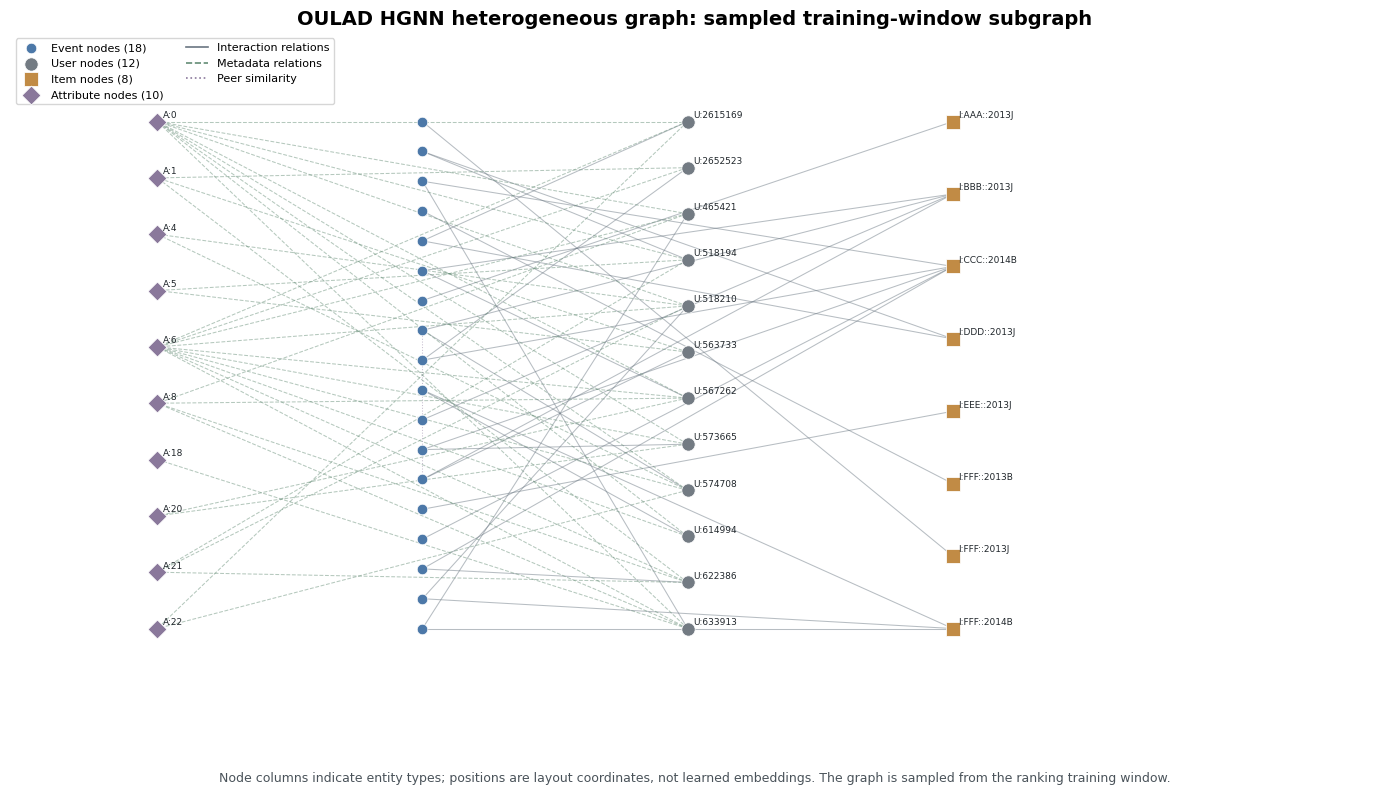

,Node type,Displayed nodes
0,Event,18
1,User,12
2,Item,8
3,Attribute,10


In [11]:
# HGNN heterogeneous-graph visualization (sampled from the training window only)
# This shows graph structure and relation types; node positions are not learned embeddings.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

_VIS_MAX_ROWS = 400
_VIS_MAX_EVENTS = 18
_vis_rng = np.random.RandomState(SEED + 202)
_vis_source = rank_history
if len(_vis_source) > _VIS_MAX_ROWS:
    _vis_source = _vis_source.sample(n=_VIS_MAX_ROWS, random_state=SEED + 202)
_vis_frame = _vis_source.reset_index(drop=True).copy()
_vis_features = dense_float32(make_preprocessor().fit_transform(_vis_frame[FEATURE_COLS]))
_vis_x, _vis_edges, _vis_meta = build_graph(_vis_frame, _vis_features)

if "n_rating_events" in _vis_meta:
    _event_count = int(_vis_meta["n_rating_events"])
    _user_start, _item_start, _tax_start = (
        int(_vis_meta["user_offset"]), int(_vis_meta["movie_offset"]), int(_vis_meta["genre_offset"])
    )
    _user_values, _item_values = _vis_meta["user_values"], _vis_meta["movie_values"]
    _taxonomy_values = _vis_meta["genre_values"]
    _attribute_start = int(_vis_meta["n_nodes"])
    _taxonomy_end = _attribute_start
    _event_label, _user_label, _item_label, _taxonomy_label = "Rating event", "User", "Movie", "Genre"
    _event_user_rel, _event_item_rel = "rating_event_to_user", "rating_event_to_movie"
    _item_tax_rel, _user_attr_rel, _peer_rel = "movie_to_genre", None, "rating_event_similarity"
elif "course_offset" in _vis_meta:
    _event_count = int(_vis_meta["n_enrollment"])
    _user_start, _item_start = int(_vis_meta["learner_offset"]), int(_vis_meta["course_offset"])
    _attribute_start = int(_vis_meta["attr_offset"])
    _taxonomy_end = _attribute_start
    _user_values, _item_values = _vis_meta["learner_values"], _vis_meta["course_values"]
    _taxonomy_values = []
    _taxonomy_label = ""
    _event_label, _user_label, _item_label = "Enrollment", "Learner", "Course presentation"
    _event_user_rel, _event_item_rel = "enrollment_to_learner", "enrollment_to_course"
    _item_tax_rel, _user_attr_rel, _peer_rel = None, "learner_to_attribute", "peer_similarity"
else:
    _event_count = int(_vis_meta["n_enrollment"])
    _user_start, _item_start = int(_vis_meta["learner_offset"]), int(_vis_meta["item_offset"])
    _tax_start, _attribute_start = int(_vis_meta["category_offset"]), int(_vis_meta["attribute_offset"])
    _taxonomy_end = _attribute_start
    _user_values, _item_values = _vis_meta["learner_values"], _vis_meta["item_values"]
    _taxonomy_values = _vis_meta["category_values"]
    _event_label, _user_label, _item_label, _taxonomy_label = "Interaction", "Customer", "Item", "Category"
    _event_user_rel, _event_item_rel = "sample_to_learner", "sample_to_item"
    _item_tax_rel, _user_attr_rel, _peer_rel = "item_to_category", "learner_to_attribute", "peer_similarity"

if _event_count == 0:
    raise ValueError("The training window contains no graph events to visualize.")
_event_candidates = np.arange(_event_count, dtype=np.int64)
_event_nodes = np.sort(_vis_rng.choice(
    _event_candidates, size=min(_VIS_MAX_EVENTS, len(_event_candidates)), replace=False
)).tolist()


def _vis_targets(relation_name, source_nodes):
    edge = _vis_edges.get(relation_name)
    if edge is None or edge.shape[1] == 0 or not source_nodes:
        return []
    keep = np.isin(edge[0], np.asarray(source_nodes, dtype=np.int64))
    return sorted(set(edge[1, keep].astype(int).tolist()))


def _vis_cap(nodes, limit):
    nodes = sorted(set(int(v) for v in nodes))
    if len(nodes) > limit:
        nodes = sorted(_vis_rng.choice(nodes, size=limit, replace=False).astype(int).tolist())
    return nodes

_user_nodes = _vis_cap(_vis_targets(_event_user_rel, _event_nodes), 12)
_item_nodes = _vis_cap(_vis_targets(_event_item_rel, _event_nodes), 14)
_taxonomy_nodes = _vis_cap(_vis_targets(_item_tax_rel, _item_nodes), 12) if _item_tax_rel else []
_attribute_nodes = _vis_cap(_vis_targets(_user_attr_rel, _user_nodes), 10) if _user_attr_rel else []
_role_nodes = {
    "event": _event_nodes,
    "user": _user_nodes,
    "item": _item_nodes,
    "taxonomy": _taxonomy_nodes,
    "attribute": _attribute_nodes,
}
_selected_nodes = set(node for values in _role_nodes.values() for node in values)

# Collect the training-graph relations for the sampled nodes; never use test labels.
_relation_specs = [
    (_event_user_rel, "interaction"), (_event_item_rel, "interaction"),
    (_item_tax_rel, "metadata"), (_user_attr_rel, "metadata"), (_peer_rel, "peer"),
    ("category_to_parent", "metadata"),
]
_vis_plot_edges = []
_vis_seen_edges = set()
for _relation_name, _edge_kind in _relation_specs:
    if not _relation_name or _relation_name not in _vis_edges:
        continue
    _edge = _vis_edges[_relation_name]
    for _src, _dst in _edge.T:
        _src, _dst = int(_src), int(_dst)
        if _src not in _selected_nodes or _dst not in _selected_nodes:
            continue
        _key = (min(_src, _dst), max(_src, _dst), _edge_kind)
        if _key not in _vis_seen_edges:
            _vis_seen_edges.add(_key)
            _vis_plot_edges.append((_src, _dst, _edge_kind))

_role_x = {"event": 0.0, "user": 1.8, "item": 3.6, "taxonomy": 5.4, "attribute": -1.8}
_vis_positions = {}
for _role, _nodes in _role_nodes.items():
    if not _nodes:
        continue
    _ys = np.linspace(1.0, -1.0, len(_nodes)) if len(_nodes) > 1 else np.asarray([0.0])
    for _node, _y in zip(sorted(_nodes), _ys):
        _vis_positions[_node] = (_role_x[_role], float(_y))


def _short_label(value, prefix, limit=12):
    return f"{prefix}:{str(value)[:limit]}"


_vis_labels = {}
for _node in _role_nodes["event"]:
    _vis_labels[_node] = ""
for _node in _role_nodes["user"]:
    _vis_labels[_node] = _short_label(_user_values[_node - _user_start], "U")
for _node in _role_nodes["item"]:
    _vis_labels[_node] = _short_label(_item_values[_node - _item_start], "I")
if _item_tax_rel:
    for _node in _role_nodes["taxonomy"]:
        _vis_labels[_node] = _short_label(_taxonomy_values[_node - _tax_start], "M")
for _node in _role_nodes["attribute"]:
    _vis_labels[_node] = f"A:{_node - _attribute_start}"

_vis_colors = {"event": "#4C78A8", "user": "#737B83", "item": "#C18B45",
               "taxonomy": "#648C75", "attribute": "#8A789B"}
_vis_markers = {"event": "o", "user": "o", "item": "s", "taxonomy": "^", "attribute": "D"}
_vis_node_role = {node: role for role, nodes in _role_nodes.items() for node in nodes}
_vis_edge_style = {"interaction": ("#697681", "-"), "metadata": ("#648C75", "--"),
                   "peer": ("#8A789B", ":")}

hgnn_graph_fig, _vis_ax = plt.subplots(figsize=(14, 8))
for _src, _dst, _kind in _vis_plot_edges:
    _color, _linestyle = _vis_edge_style[_kind]
    _x0, _y0 = _vis_positions[_src]
    _x1, _y1 = _vis_positions[_dst]
    _vis_ax.plot([_x0, _x1], [_y0, _y1], color=_color, linestyle=_linestyle,
                 linewidth=0.75, alpha=0.48, zorder=1)
for _role, _nodes in _role_nodes.items():
    if not _nodes:
        continue
    _xs = [_vis_positions[node][0] for node in _nodes]
    _ys = [_vis_positions[node][1] for node in _nodes]
    _vis_ax.scatter(_xs, _ys, s=92 if _role != "event" else 58,
                    marker=_vis_markers[_role], color=_vis_colors[_role],
                    edgecolors="white", linewidths=0.55, zorder=2,
                    label=f"{_role.title()} nodes ({len(_nodes)})")
    for _node in _nodes:
        _x, _y = _vis_positions[_node]
        _label = _vis_labels.get(_node, "")
        if _label:
            _vis_ax.annotate(_label, (_x, _y), xytext=(4, 3), textcoords="offset points",
                             fontsize=6.5, color="#20262B", zorder=3)
_vis_edge_legend = [
    Line2D([0], [0], color=_vis_edge_style["interaction"][0], lw=1.2, label="Interaction relations"),
    Line2D([0], [0], color=_vis_edge_style["metadata"][0], lw=1.2, ls="--", label="Metadata relations"),
    Line2D([0], [0], color=_vis_edge_style["peer"][0], lw=1.2, ls=":", label="Peer similarity"),
]
_vis_handles, _vis_labels_legend = _vis_ax.get_legend_handles_labels()
_vis_ax.legend(_vis_handles + _vis_edge_legend, _vis_labels_legend + [h.get_label() for h in _vis_edge_legend],
               loc="upper left", frameon=True, fontsize=8, ncol=2)
_vis_ax.set_title("OULAD HGNN heterogeneous graph: sampled training-window subgraph", fontsize=14, weight="semibold")
_vis_ax.text(0.5, -0.08,
             "Node columns indicate entity types; positions are layout coordinates, not learned embeddings. "
             "The graph is sampled from the ranking training window.",
             transform=_vis_ax.transAxes, ha="center", va="top", fontsize=9, color="#4A535A")
_vis_ax.set_xlim(-2.8, 6.5)
_vis_ax.set_ylim(-1.35, 1.35)
_vis_ax.axis("off")
hgnn_graph_fig.tight_layout()
hgnn_graph_fig.savefig(OUTPUT_DIR / "oulad_hgnn_heterogeneous_graph_schema.png", dpi=180, bbox_inches="tight")
display(hgnn_graph_fig)
plt.close(hgnn_graph_fig)

hgnn_graph_summary = pd.DataFrame([
    {"Node type": role.title(), "Displayed nodes": len(nodes)} for role, nodes in _role_nodes.items() if nodes
])
display(hgnn_graph_summary)


In [12]:
# Recommendation Dashboard (Gradio) - 100% dynamically driven from computed model rankings
import importlib.util

if importlib.util.find_spec("gradio") is None:
    print("Gradio is not installed. Install it with `pip install gradio`, then rerun this cell.")
else:
    import gradio as gr

    _recommendation_rows = globals().get("temporal_top5", pd.DataFrame()).copy()
    _user_col = next((c for c in ["User_ID", "Student_ID"] if c in _recommendation_rows.columns), None)
    _item_col = next((c for c in ["Item_ID", "Recommended_Module"] if c in _recommendation_rows.columns), None)
    _required_cols = {_user_col, _item_col, "Model", "Seed", "Rank"}

    if _recommendation_rows.empty or None in _required_cols or not _required_cols.issubset(_recommendation_rows.columns):
        print("No saved top-5 recommendations are available. Run the temporal recommendation evaluation cell first.")
    else:
        _models_available = sorted(_recommendation_rows["Model"].dropna().unique().tolist())
        _user_choices = sorted(_recommendation_rows[_user_col].dropna().astype(str).unique().tolist())

        def _show_recommendations(user_id, model_name):
            _empty = pd.DataFrame(columns=["Rank", "Recommended_Module", "Seed_Votes", "Mean_Rank"])
            if not user_id or not model_name:
                return _empty
            _user_rows = _recommendation_rows.loc[
                _recommendation_rows[_user_col].astype(str).eq(str(user_id)) &
                _recommendation_rows["Model"].astype(str).eq(str(model_name))
            ]
            if _user_rows.empty:
                return _empty
            _consensus = (
                _user_rows.groupby(_item_col, as_index=False)
                .agg(Seed_Votes=("Seed", "nunique"), Mean_Rank=("Rank", "mean"))
                .sort_values(["Seed_Votes", "Mean_Rank", _item_col], ascending=[False, True, True])
                .head(5)
            )
            return pd.DataFrame({
                "Rank": range(1, len(_consensus) + 1),
                "Recommended_Module": _consensus[_item_col].astype(str).to_numpy(),
                "Seed_Votes": _consensus["Seed_Votes"].to_numpy(),
                "Mean_Rank": _consensus["Mean_Rank"].round(2).to_numpy(),
            })

        with gr.Blocks(title="OULAD Course Recommendations") as recommendation_dashboard:
            gr.Markdown("# OULAD Course Recommendations Dashboard\nSelect a student and model (Standard HGNN vs. Risk-Aware HGNN) to view genuine top-5 model recommendations computed from evaluation seeds.")
            with gr.Row():
                _user_selector = gr.Dropdown(
                    choices=_user_choices,
                    value=_user_choices[0] if _user_choices else None,
                    label="Select Student ID",
                    filterable=True,
                )
                _model_selector = gr.Dropdown(
                    choices=_models_available,
                    value="HGNN (Risk-Aware)" if "HGNN (Risk-Aware)" in _models_available else _models_available[0],
                    label="Select Model",
                )
            _recommendation_table = gr.Dataframe(
                value=_show_recommendations(_user_choices[0] if _user_choices else None,
                                            "HGNN (Risk-Aware)" if "HGNN (Risk-Aware)" in _models_available else _models_available[0]),
                label="Computed Top-5 Recommendations",
                interactive=False,
                wrap=True,
            )
            _user_selector.change(
                _show_recommendations,
                inputs=[_user_selector, _model_selector],
                outputs=_recommendation_table,
            )
            _model_selector.change(
                _show_recommendations,
                inputs=[_user_selector, _model_selector],
                outputs=_recommendation_table,
            )

        recommendation_dashboard.launch(share=True, inline=True, show_error=True)


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://a88017513bbd5ea086.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
